# Looking at predicted Argus detections of SSOs

SSO detection predictions generated by Donovan Schlekat with `kete`

*for Katie: running this notebook in an hdps venv*

*Open files with __[pyarrow](https://arrow.apache.org/docs/python/parquet.html)__ and convert to pandas dataframe, or just use __[pandas](https://pandas.pydata.org/docs/reference/api/pandas.read_parquet.html)__ to open*

In [1]:
from astropy.coordinates import SkyCoord
from astropy.table import *
from astropy.time import Time
import glob
import matplotlib.pyplot as plt
from numba import njit, prange
import numpy as np 
import numpy.polynomial.chebyshev as npcheb
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import random
from scipy.interpolate import CubicSpline
import time

from hdps.core import argus_epoch,argus_epoch_to_datetime,datetime_to_argus_epoch # argus epoch = seconds since 2025
from hdps.skymap import TanSegmentLookup, SegmentationScheme

# .Descriptions

## ..202606 sample:

Currently in the directory at "ephem_path" there are the following:

- 7 parquet files with names "ephemerides_YYYY-MM-DD.parquet" (~7.3GB each, 1 day per file, 7 days total)
    - these contain, for each object, the generated RA/Dec for the entire night, cadence depends on object proper motion.  
    - time scale is TT, time format is the __[Argus epoch](https://github.com/argus-hdps/hdps/blob/main/docs/source/components/core/explanation/data-conventions.md)__ = TT seconds since 2025-01-01 00:00:00.000 TT

- one timing_summary.csv file (728B).

## ..202607 sample:

*Donovan said the following on 20260708:*

"new ephemeris samples with the new data storage scheme are available in `/net/scratch/dschlekat/ephemeris_samples2`.  Note that this is not ephemerides for every object: it only includes ephemerides for objects that will rise above 27.5 deg in altitude above McDonald on a given night during observable hours (sun altitude < -18 deg).  Ephemerides are saved with an adaptive cadence strategy: quick-moving objects have their ephemerides saved at higher cadence; slower objects have their positions sampled more sparsely."

`ephemerides.parquet` : per-epoch ephemeris table (multiple rows per object), sorted by object designation then by epoch

Note: While this is enough for determining which minipixes to put into the input catalog, if we want to determine the position of objects at a particular image’s epoch (i.e. for source cross-matching), fast moving objects will require a bit more than just grabbing the nearest record. It is more precise (and is approximately as precise as using a full propagator) to grab the two records bounding a given epoch and linearly interpolating in between (hopefully this makes sense).

`objects.parquet` : 
per-object nightly orbital snapshot
- designation (dict), x,y,z (AU), vx,vy,vz (AU/day): heliocentric-ecliptic Cartesian state at the night anchor (midnight); state_argus_epoch (int64 µs TT) is that anchor. 
- Photometry: h_mag,g_phase (asteroid H/G; null for comets), m1,k1,m2,k2 (comet total-mag params; null for asteroids), all float32. 
- Table metadata: catalog_source, kete_version . We can add additional columns here if we’d want to attach other things to alerts, like orbital family, flags for anomalies, etc.
- argus epoch in microseconds? "It's supposed to be Argus epoch (units of seconds) with microsecond precision, but the way I stored it (int32) basically makes it Argus epoch (units of microseconds). Dividing that column by ~~100000~~ [1,000,000, really] gives Argus epoch (units of seconds)"

`properties.parquet` : per-object degree-3 Chebyshev coefficients for approximations describing orbital geometry and predicted visible magnitude
Degree-3 Chebyshev coefficients over the night for r (AU), delta = Δ (AU), alpha = α phase angle (deg), V (mag): columns <q>_c0..c3.

- "I’m just now realizing this makes it far less trivial than it should to filter from all objects within the FOV -> all objects within the FOV that will be brighter than V = 22. While you could compute that from the properties table, it’s already computed to create that table, so I am going to edit the code to stick a new column into objects: v_peak, or peak magnitude within a night, so it’s easier to make that first filter."
    - v_peak is the brightest an object will get in a night 


**Example of how to evaluate predicted V for an object at an Argus epoch t (µs):**

"The use of a Chebyshev approximation allows orbital geometry and predicted visual magnitude to be calculated cheaply at the exact epoch of a detection. In a single night these quantities are slow scalars that can be approximated with minimal loss (r/α ~machine precision, Δ < ~1e-6 AU, V < ~1e-3 mag). I can save it in a different way but this is what I settled on after iteration with Claude. I was originally using quadratics but this was more accurate and used less anchors to create.

"objects.parquet and properties.parquet allow us to easily attach object metadata and orbital information that isn’t needed for the actual ephemeris to alerts of detections, which David said is very useful to have for downstream analysis, while keeping the ephemeris table as lean as possible.

# .Load samples and explore

## ..202606 sample

In [3]:
ephem_path = "/net/scratch/dschlekat/ephemeris_samples" # 202606 sample
ephem_files = glob.glob(ephem_path+"/*.parquet")

In [4]:
#ephem_test = Table.read(ephem_files[0],format="parquet") # Does not work with astropy; file too big
##ephem_test_pa = pq.read_table(ephem_files[0])
##ephem_test = ephem_test_pa.to_pandas()
ephem_test = pd.read_parquet(ephem_files[0])

In [5]:
ephem_test

,designation,ra_deg,dec_deg,V_mag,epoch_tt,cadence_s
0,100,332.973893,-11.265691,12.606252,44595000.0,60.0
1,100,332.974042,-11.265663,12.606243,44595060.0,60.0
2,100,332.974192,-11.265634,12.606233,44595120.0,60.0
3,100,332.974342,-11.265606,12.606224,44595180.0,60.0
4,100,332.974491,-11.265578,12.606214,44595240.0,60.0
...,...,...,...,...,...,...
316775115,99P,338.047246,-13.453755,NaN,44619300.0,60.0
316775116,99P,338.047273,-13.453750,NaN,44619360.0,60.0
316775117,99P,338.047300,-13.453746,NaN,44619420.0,60.0
316775118,99P,338.047327,-13.453741,NaN,44619480.0,60.0


In [5]:
print(len(ephem_test['designation'].unique())," unique objects in file ",ephem_files[0])

759655  unique objects in file  /net/scratch/dschlekat/ephemeris_samples/ephemerides_2026-06-01.parquet


In [7]:
(len(ephem_test['epoch_tt'].unique())*15)/60/60

20.454166666666666

In [7]:
min_epoch = argus_epoch_to_isot(ephem_test['epoch_tt'].min())
max_epoch = argus_epoch_to_isot(ephem_test['epoch_tt'].max())
min_epoch,max_epoch

('2026-06-01T03:30:00.000', '2026-06-01T10:19:00.000')

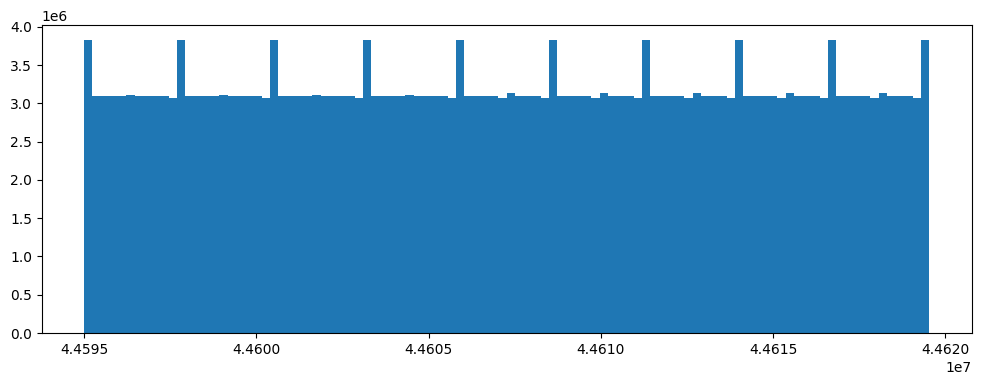

In [12]:
plt.figure(figsize=(12,4))
plt.hist(ephem_test['epoch_tt'],bins=100)
plt.show()

## ..202607 sample

In [2]:
ephem_path = "/net/scratch/dschlekat/ephemeris_samples3" # updated 202607 sample
# ephemeris_samples2 has the same stuff but not with v_peak in the objects table, and also it is june not july
ephem_diros = glob.glob(ephem_path+"/2026*")
ephem_diros

['/net/scratch/dschlekat/ephemeris_samples3/2026-07-01',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-02',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-03',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-04',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-05',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-06',
 '/net/scratch/dschlekat/ephemeris_samples3/2026-07-07']

In [3]:
# summary file
summary = Table.read(ephem_path+"/summary.csv",format="csv")
summary

date,n_states,n_survivors,n_objects,night_window_s,orbit_propagation_s,mag_pre_cut_s,probe_rates_s,altitude_cut_s,cadence_assignment_s,build_objects_s,build_properties_s,cadence_loop_s,pipeline_s,parquet_write_s,total_s,ephemerides_bytes,objects_bytes,properties_bytes,total_bytes
str10,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64
2026-07-01,1556391,741594,305564877,0.7243,235.2932,0.0,43.7115,112.2556,0.0067,39.6648,0.1804,241.6242,812.4541,42.9748,1091.4475,823714112,41574652,95069213,960357977
2026-07-02,1556391,741318,306478838,0.2187,195.5778,0.0,20.5804,6.7502,0.0049,4.4492,0.171,247.108,723.3026,43.3437,962.4436,826389633,41555039,95043835,962988507
2026-07-03,1556391,741221,307427754,0.2108,195.7439,0.0,20.7293,6.7898,0.0047,4.5506,0.1725,241.2303,606.9631,42.0152,844.9336,829060649,41550838,95037563,965649050
2026-07-04,1556391,740669,308250939,0.2105,193.7955,0.0,19.5393,6.3308,0.0043,3.5093,0.168,237.1831,693.8393,44.0862,931.9322,830037779,41526078,94958790,966522647
2026-07-05,1556391,738325,307333935,0.2105,194.1309,0.0,21.631,7.1045,0.0045,3.8372,0.1722,234.8754,683.5362,42.1922,920.0705,827357062,41400422,94676132,963433616
2026-07-06,1556391,737641,308071992,0.2102,194.5457,0.0,19.3757,6.3811,0.0045,3.4837,0.1706,253.818,705.6622,44.1293,944.5482,826033140,41371233,94585915,961990288
2026-07-07,1556391,738938,310484558,0.2119,194.4308,0.0,19.5518,7.3261,0.0045,3.6556,0.1705,249.9026,685.5041,44.5639,924.7115,833824319,41442249,94740371,970006939


In [22]:
night_diro = ephem_diros[0]
night_ephems = pd.read_parquet(night_diro+"/ephemerides.parquet")
night_objects = pd.read_parquet(night_diro+"/objects.parquet")
night_properties = pd.read_parquet(night_diro+"/properties.parquet")

In [20]:
len(night_objects)

741594

In [ ]:
night_objects_magcut = night_objects.loc[(night_objects['v_peak']<=20)]# & (night_objects['v_peak']>=16)]
keep_desigs = np.unique(night_objects_magcut['designation'])

array(['100', '1000', '10000', ..., '99993', '99996', '99997'],
      shape=(51840,), dtype=object)

26.13% of objects in night 1 make the V_peak <= 21.5 mag cut


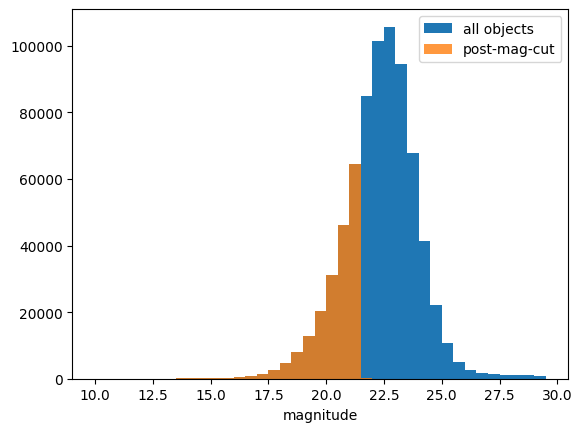

In [30]:
print(f"{(len(night_objects_magcut)/len(night_objects)*100):.2f}% of objects in night 1 make the V_peak <= 21.5 mag cut")

plt.hist(night_objects['v_peak'],bins=np.arange(10,30,0.5),label="all objects")
plt.hist(night_objects_magcut['v_peak'],bins=np.arange(10,30,0.5),alpha=0.8,label="post-mag-cut")
plt.legend()
plt.xlabel("magnitude")
plt.show()

In [6]:
night_ephems_magcut = night_ephems[night_ephems['designation'].isin(night_objects_magcut['designation'])] 
night_ephems_magcut

,designation,ra,dec,epoch_tt
0,100,1213628345,-39592247,47187660000000
1,100,1213628492,-39592321,47187720000000
2,100,1213628640,-39592394,47187780000000
3,100,1213628788,-39592468,47187840000000
4,100,1213628935,-39592542,47187900000000
...,...,...,...,...
305564872,99P,1217556292,-49087021,47211360000000
305564873,99P,1217556212,-49087068,47211420000000
305564874,99P,1217556132,-49087116,47211480000000
305564875,99P,1217556052,-49087163,47211540000000


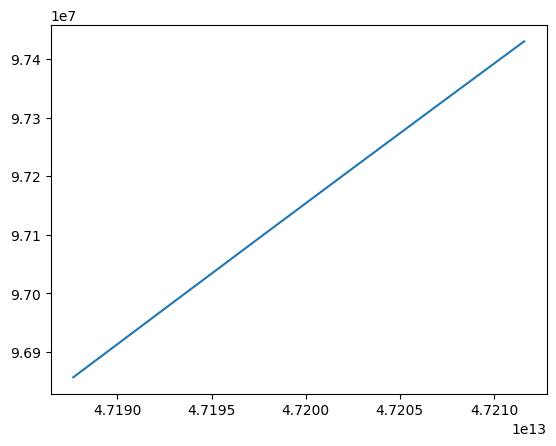

In [9]:
weirdo = night_ephems_magcut[night_ephems_magcut['designation']=='10000']
plt.plot(weirdo['epoch_tt'],weirdo['ra'])
plt.show()

In [7]:
night_ephems_magcut[night_ephems_magcut['designation']=='10000']

,designation,ra,dec,epoch_tt
800,10000,96856829,30908802,47187660000000
801,10000,96857554,30908847,47187690000000
802,10000,96858278,30908892,47187720000000
803,10000,96859003,30908937,47187750000000
804,10000,96859727,30908983,47187780000000
...,...,...,...,...
1594,10000,97427262,30944826,47211480000000
1595,10000,97427973,30944871,47211510000000
1596,10000,97428684,30944916,47211540000000
1597,10000,97429396,30944961,47211570000000


In [11]:
print(f"{100*(len(night_ephems_magcut)/len(night_ephems)):.2f} % of rows from ephemeris samples represent objects that made the mag cut")

25.99 % of rows from ephemeris samples represent objects that made the mag cut


In [12]:
night_properties_magcut = night_properties.loc[night_objects['v_peak']<=21.5]
night_properties_magcut

,designation,r_c0,r_c1,r_c2,r_c3,delta_c0,delta_c1,delta_c2,delta_c3,alpha_c0,alpha_c1,alpha_c2,alpha_c3,V_c0,V_c1,V_c2,V_c3
0,100,2.572921,0.000021,3.588744e-08,-1.136369e-12,1.858853,-0.001419,4.058304e-06,7.989653e-07,19.045079,-0.030365,-0.000181,0.000017,12.097382,-0.002620,-1.500872e-06,1.476652e-06
1,1000,3.327673,0.000324,-1.419076e-08,-1.371110e-11,3.283797,-0.001634,-4.424892e-08,9.251094e-07,17.673960,0.002134,-0.000121,-0.000002,16.746829,-0.000799,-4.169340e-06,5.525170e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741592,99997,2.283825,-0.000308,-1.502140e-08,1.339172e-11,1.440194,-0.001468,5.183036e-06,6.703950e-07,17.994419,-0.044565,-0.000200,0.000028,19.570223,-0.003971,3.742776e-07,1.921698e-06
741593,99P,6.643821,0.000186,-4.249809e-09,-6.460335e-12,6.018828,-0.001662,4.092220e-06,8.013560e-07,7.269571,-0.012147,-0.000058,0.000005,20.466574,-0.000453,1.430682e-06,2.893067e-07


## Chebyshev with Python

numpy provides __[Chebyshev functionality](https://numpy.org/doc/stable/reference/routines.polynomials.chebyshev.html )__

and the __[`Chebyshev` class](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.chebyshev.Chebyshev.html)__ can hold coefficients  order of increasing degree, i.e., `coef=(1, 2, 3)` gives `1*T_0(x) + 2*T_1(x) + 3*T_2(x)` and you can use __[`chebval()`](https://numpy.org/devdocs/reference/generated/numpy.polynomial.chebyshev.chebval.html)__ to evaluate an expansion with coefficients, at point x

In [ ]:
# fitting to a polynomial?  If you want.  Not needed, but interesting feature.
cheby_example = npcheb.Chebyshev(coef=(1,2,3,4))
coef_poly = np.polynomial.chebyshev.cheb2poly(cheby_example.coef)
poly = np.polynomial.Polynomial(coef_poly)
print(cheby_example,"\n",poly)

1.0 + 2.0·T₁(x) + 3.0·T₂(x) + 4.0·T₃(x) 
 -2.0 - 10.0·x + 6.0·x² + 16.0·x³


Get the r, delta, alpha, V values for the first object in the properties table, on the first night, at the night midpoint:

In [ ]:
cheby_r = npcheb.Chebyshev(coef=(night_properties['r_c0'][0],night_properties['r_c1'][0],night_properties['r_c2'][0],night_properties['r_c3'][0]))
cheby_delta = npcheb.Chebyshev(coef=(night_properties['delta_c0'][0],night_properties['delta_c1'][0],night_properties['delta_c2'][0],night_properties['delta_c3'][0]))
cheby_alpha = npcheb.Chebyshev(coef=(night_properties['alpha_c0'][0],night_properties['alpha_c1'][0],night_properties['alpha_c2'][0],night_properties['alpha_c3'][0]))
cheby_v = npcheb.Chebyshev(coef=(night_properties['V_c0'][0],night_properties['V_c1'][0],night_properties['V_c2'][0],night_properties['V_c3'][0]))
print(f"r of object {night_properties['designation'][0]} at t=0 is {npcheb.chebval(0,cheby_r.coef)}")
print(f"delta of object {night_properties['designation'][0]} at midpoint time x=0 is {npcheb.chebval(0,cheby_delta.coef)}")
print(f"alpha of object {night_properties['designation'][0]} at midpoint time x=0 is {npcheb.chebval(0,cheby_alpha.coef)}")
print(f"V mag of object {night_properties['designation'][0]} at midpoint time x=0 is {npcheb.chebval(0,cheby_v.coef)}")

r of object 100 at t=0 is 2.571831416797053
delta of object 100 at midpoint time x=0 is 2.201519544108158
alpha of object 100 at midpoint time x=0 is 22.88030671721623
V mag of object 100 at midpoint time x=0 is 12.584281848051662


Use Donovan's example code to calculate V for the first object in the night properties table, on the first night, at a specific time as given by Argus epoch:

In [24]:
night_props  = pq.read_table(night_diro+"/properties.parquet")
meta = night_props.schema.metadata       # night interval lives in the metadata`
t0   = int(meta[b"t0_epoch_tt_us"]) #"t0_argus_epoch_us"])
t1   = int(meta[b"t1_epoch_tt_us"])
df   = night_props.to_pandas()

# Map detection epoch t (Argus TT microseconds) to Chebyshev domain x [-1, 1].
t = 47_197_660_000_000 # 44_600_000_000_000 # time in argus epoch museconds that you want the object values at, between t0 & t1
x = 2 * (t - t0) / (t1 - t0) - 1

#--- one object's V ---
row = df.iloc[0]  # or: df[df.designation == "..."].iloc[0]
V = npcheb.chebval(x, [row.V_c0, row.V_c1, row.V_c2, row.V_c3])  # apparent V (mag)
print(f"object {df['designation'][0]} V mag at datetime {argus_epoch_to_datetime(t/1000000)} is {V}")

object 100 V mag at datetime 2026-07-01 06:27:40 is 12.097815593088193


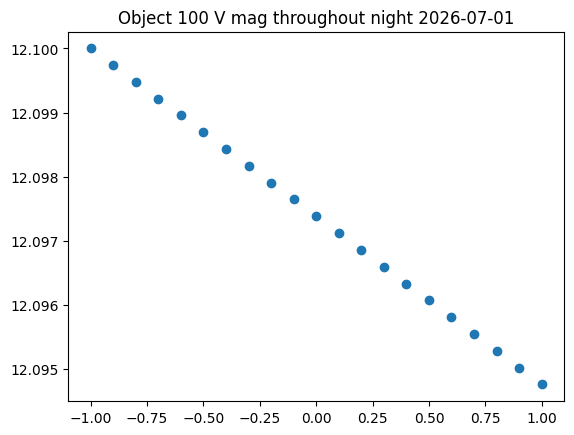

In [26]:
plt.title(f"Object {night_properties['designation'][0]} V mag throughout night {night_diro.split("/")[-1]}")
xset = np.arange(-1,1.1,0.1)
#ts = np.arange(argus_epoch_to_datetime(t0),argus_epoch_to_datetime(t1),len(xset))
plt.scatter(xset,npcheb.chebval(xset,[row.V_c0, row.V_c1, row.V_c2, row.V_c3]))
plt.ticklabel_format(useOffset=False,style="plain")
plt.show()

In [27]:
npcheb.chebval(xset,[row.V_c0, row.V_c1, row.V_c2, row.V_c3])

array([12.09999938, 12.0997391 , 12.09947844, 12.09921743, 12.09895612,
       12.09869453, 12.09843271, 12.09817069, 12.0979085 , 12.09764618,
       12.09738376, 12.09712129, 12.09685878, 12.09659629, 12.09633385,
       12.09607149, 12.09580924, 12.09554715, 12.09528525, 12.09502356,
       12.09476214])

# .Generating object positions in Argus images
To get the minipix that need to be activated at the epoch of each image, I need to get the coordinstes of each object that we predict will be detected in each Argus image, at the epoch of each image.  

In [11]:
def t_to_x(t,t0,t1):
    '''
    Turn argus epoch into Chebyshev x [-1,1]
    '''
    x = 2 * (t - t0) / (t1 - t0) - 1
    return(x)

In [ ]:
# generate target epochs
night_props  = pq.read_table(night_diro+"/properties.parquet")
meta = night_props.schema.metadata       # night interval lives in the metadata`
t0   = int(meta[b"t0_epoch_tt_us"]) 
t1   = int(meta[b"t1_epoch_tt_us"])
df   = night_props.to_pandas()
target_epochs = np.arange(t0/1000000,(t1/1000000)+60,60) # rough epochs of Argus images for 1 night (1min cadence all night)
#print([argus_epoch_to_datetime(i) for i in target_epochs][1]) # just making sure these are spaced 1 min apart
#target_xs = t_to_x(target_epochs*1000000,t0,t1) # turn them into cheby x, not needed?

interpolate with scipy CubicSpline https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html


In [16]:
desig = "10000"
desig_ephem_sample = night_ephems.loc[night_ephems['designation']==desig] #night_ephems[night_ephems['designation']=="100"]

times = desig_ephem_sample['epoch_tt']/1000000
x_coords = np.array(desig_ephem_sample['ra'])
y_coords = np.array(desig_ephem_sample['dec'])
positions = np.vstack((x_coords,y_coords))
trajectory_spline = CubicSpline(times,positions,axis=1,bc_type="natural")

interpolated_positions = trajectory_spline(target_epochs)
interpolated_positions
#np.interp(target_epochs,desig_ephem_sample['ra'],desig_ephem_sample['dec'])

array([[96856829., 96858278., 96859727., 96861176., 96862625., 96864073.,
        96865522., 96866971., 96868419., 96869868., 96871316., 96872765.,
        96874214., 96875662., 96877110., 96878559., 96880007., 96881456.,
        96882904., 96884352., 96885800., 96887248., 96888697., 96890145.,
        96891593., 96893041., 96894489., 96895937., 96897385., 96898832.,
        96900280., 96901728., 96903176., 96904623., 96906071., 96907519.,
        96908966., 96910414., 96911861., 96913309., 96914756., 96916204.,
        96917651., 96919098., 96920545., 96921993., 96923440., 96924887.,
        96926334., 96927781., 96929228., 96930675., 96932121., 96933568.,
        96935015., 96936462., 96937908., 96939355., 96940802., 96942248.,
        96943695., 96945141., 96946587., 96948034., 96949480., 96950926.,
        96952372., 96953819., 96955265., 96956711., 96958157., 96959602.,
        96961048., 96962494., 96963940., 96965386., 96966831., 96968277.,
        96969722., 96971168., 96972613

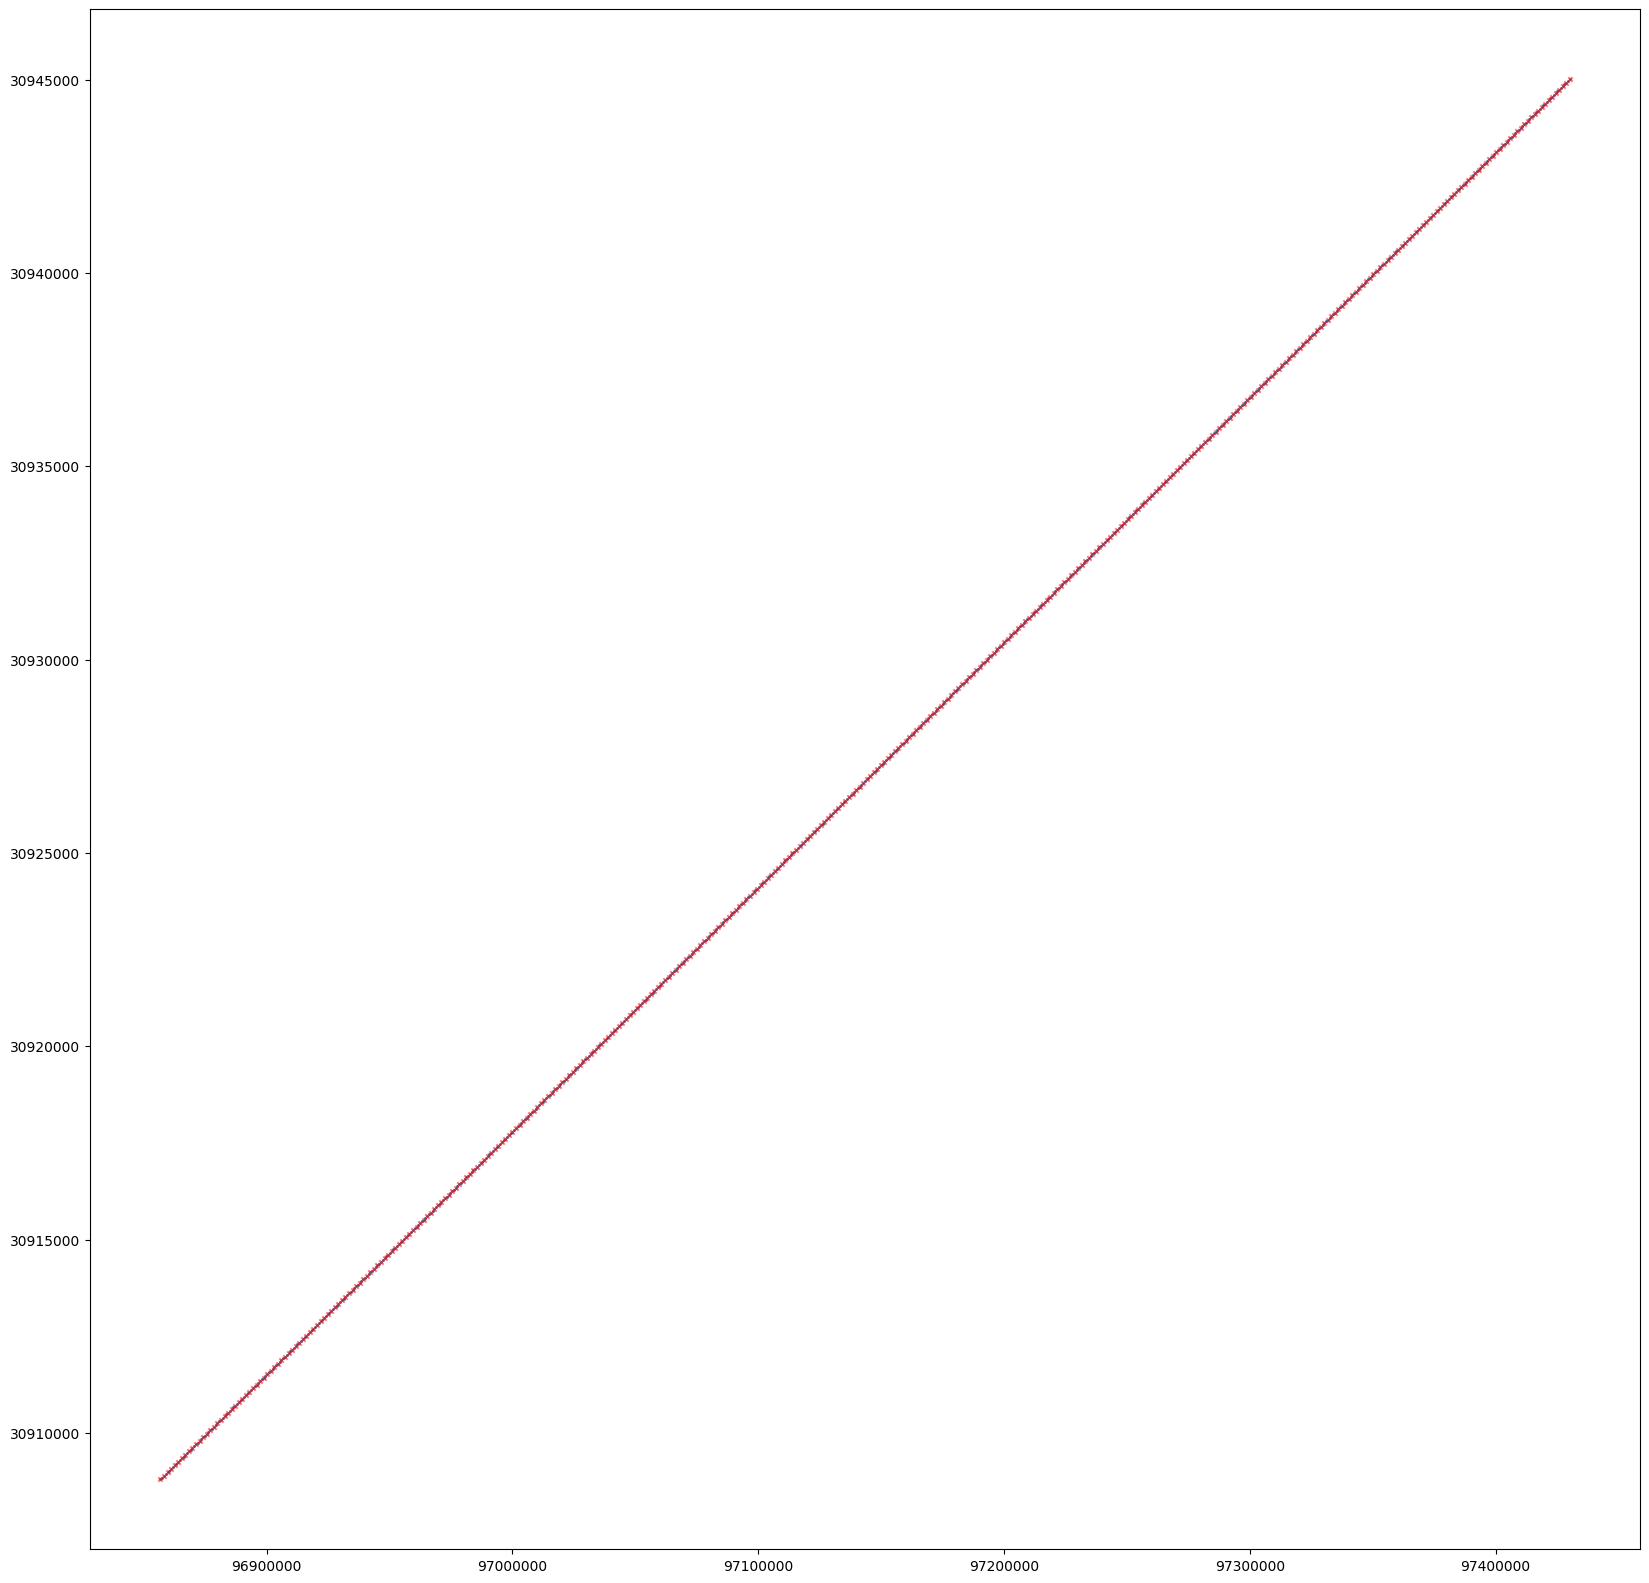

In [17]:
plt.figure(figsize=(20,20))
plt.scatter(desig_ephem_sample['ra'],desig_ephem_sample['dec'],s=1)
plt.scatter(interpolated_positions[0],interpolated_positions[1],c="red",marker="x",alpha=0.5,s=10)
plt.ticklabel_format(useOffset=False,style="plain")
plt.show()

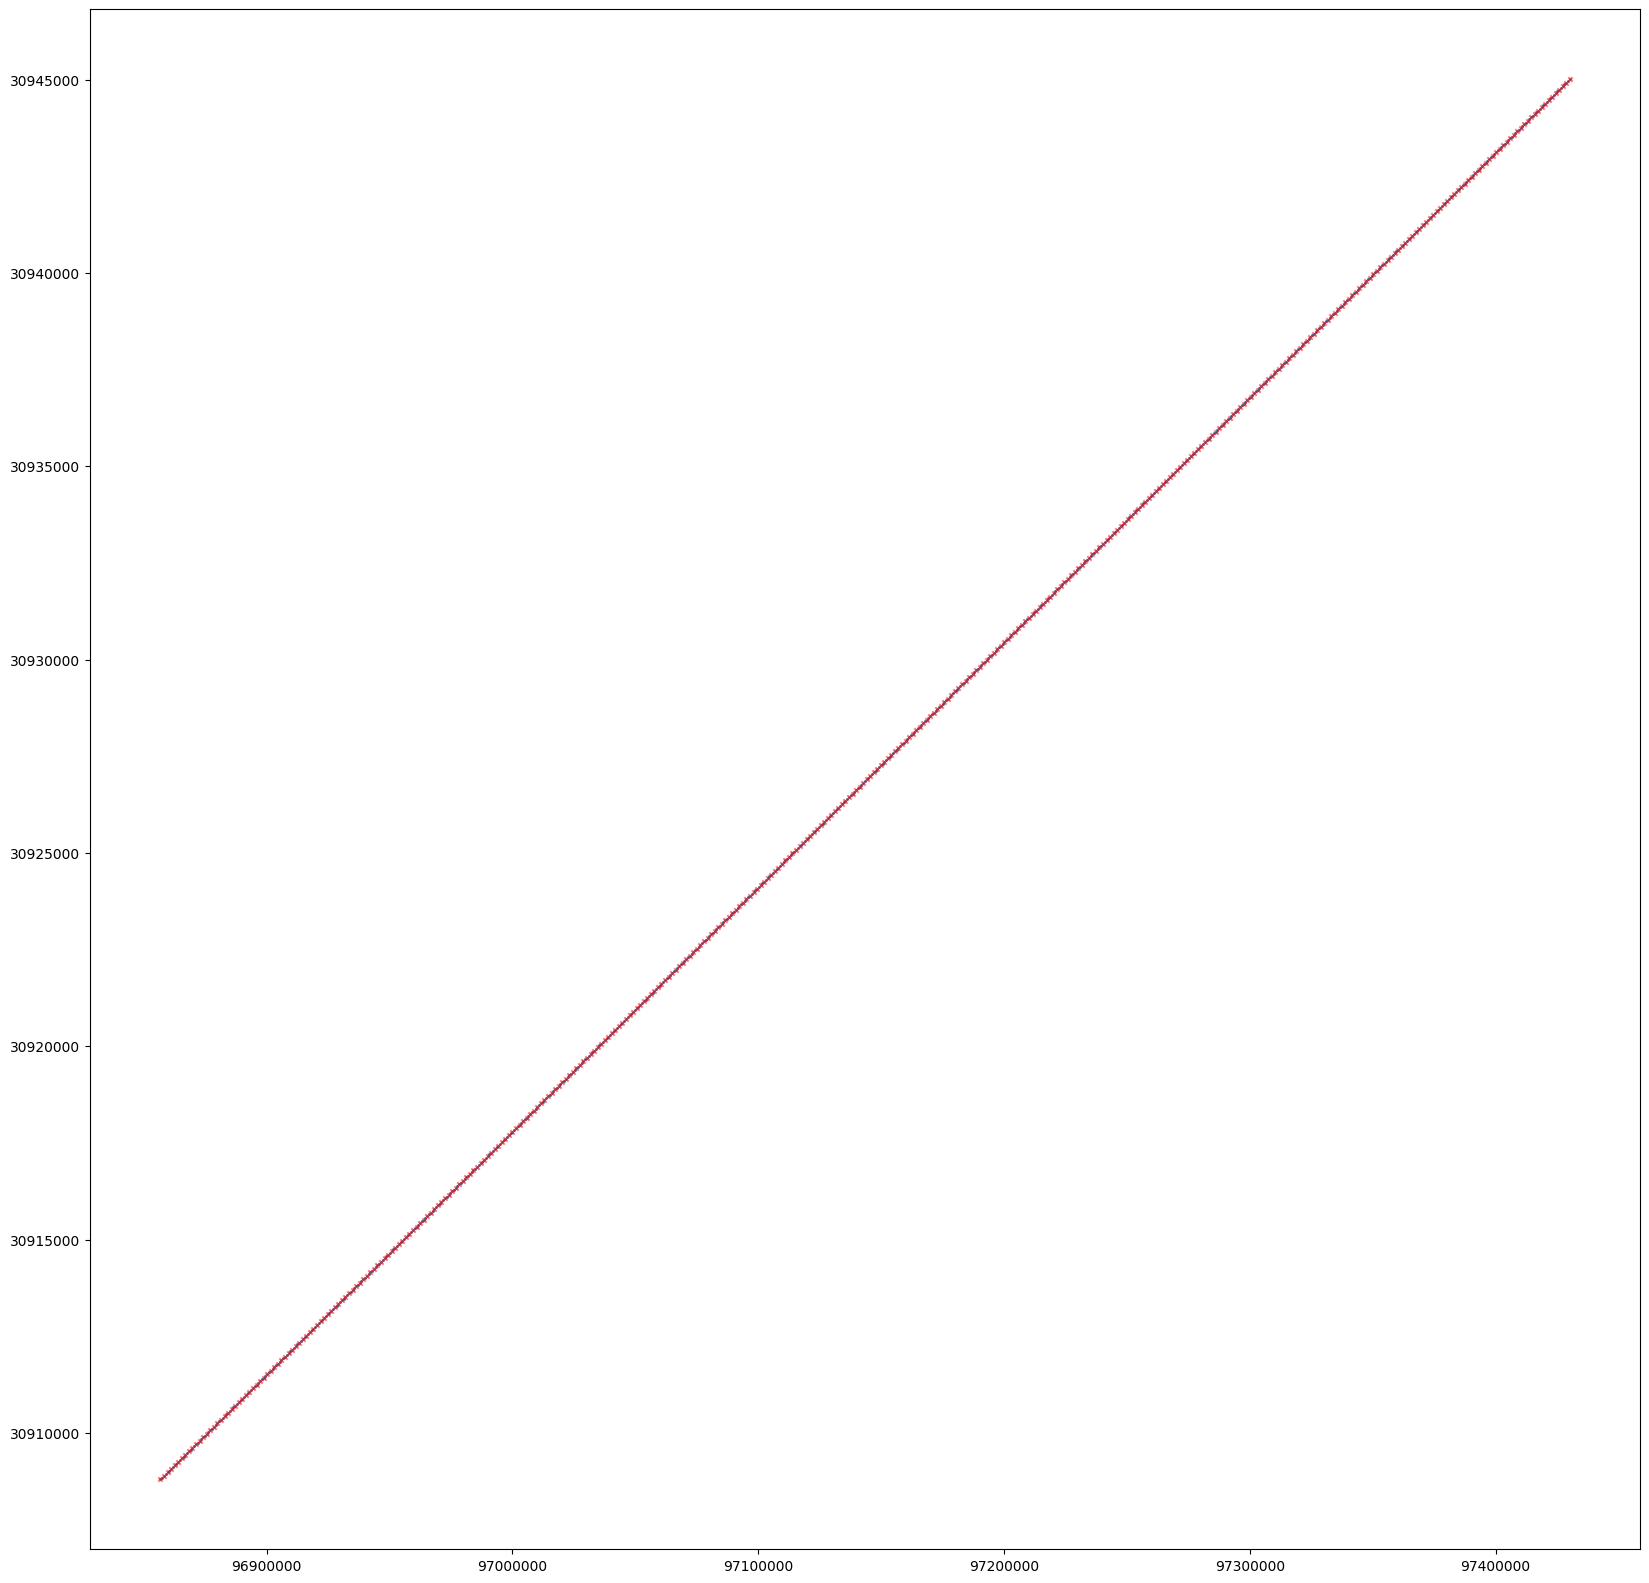

In [20]:
#interpolate wiht numpy 
desig = "10000"
desig_ephem_sample = night_ephems.loc[night_ephems['designation']==desig] #night_ephems[night_ephems['designation']=="100"]

times = desig_ephem_sample['epoch_tt']/1000000
x_coords = np.array(desig_ephem_sample['ra'])
y_coords = np.array(desig_ephem_sample['dec'])
x_interp = np.interp(target_epochs,times,x_coords)
y_interp = np.interp(target_epochs,times,y_coords)

interpolated_positions = [x_interp,y_interp]

plt.figure(figsize=(20,20))
plt.scatter(desig_ephem_sample['ra'],desig_ephem_sample['dec'],s=1)
plt.scatter(interpolated_positions[0],interpolated_positions[1],c="red",marker="x",alpha=0.5,s=10)
plt.ticklabel_format(useOffset=False,style="plain")
plt.show()

In [ ]:
# trying a manual interpolation, this is not ideal
ndets = [] #"col == 'value'"
start = time.time()
target_epoch = target_epochs[200]
for desig in night_objects_magcut['designation']:
    desig_ephem_sample = night_ephems.loc[night_ephems['designation']==desig] #night_ephems[night_ephems['designation']=="100"]
    #desig_properties = night_properties.loc[night_properties['designation']==desig]
    
    closest_idx = np.abs((desig_ephem_sample['argus_epoch']/1000000) - target_epoch).argmin()
    print("closest_idx = ",closest_idx)
    closest_point = desig_ephem_sample.loc[closest_idx]
    print("designation = ",desig,"sample = ",min(abs((desig_ephem_sample['argus_epoch']/1000000) - target_epoch)))


    # interpolate ephemeris to target epochs
    #times = desig_ephem_sample['argus_epoch']/1000000
    #x_coords = np.array(desig_ephem_sample['ra'])
    #y_coords = np.array(desig_ephem_sample['dec'])
    #positions = np.vstack((x_coords,y_coords))
    #trajectory_spline = CubicSpline(times,positions,axis=1,bc_type="natural")
    #interpolated_positions = trajectory_spline(target_epochs)

    # interpolate Vmag to target epochs
    #vmag = npcheb.chebval(x, [desig_properties.V_c0, desig_properties.V_c1, desig_properties.V_c2, desig_properties.V_c3])  # apparent V (mag)


    designation          ra       dec     argus_epoch
0           100  1198706013 -40556488  44595000000000
1           100  1198706552 -40556386  44595060000000
2           100  1198707091 -40556284  44595120000000
3           100  1198707630 -40556182  44595180000000
4           100  1198708169 -40556079  44595240000000
..          ...         ...       ...             ...
405         100  1198918786 -40515520  44619300000000
406         100  1198919298 -40515419  44619360000000
407         100  1198919810 -40515317  44619420000000
408         100  1198920323 -40515216  44619480000000
409         100  1198920835 -40515114  44619540000000

[410 rows x 4 columns]
closest_idx =  200
designation =  100 sample =  0.0
    designation        ra       dec     argus_epoch
410        1000  16589735  43961311  44595000000000
411        1000  16590262  43961744  44595060000000
412        1000  16590790  43962177  44595120000000
413        1000  16591318  43962611  44595180000000
414        1000 

KeyError: np.int64(200)

# .Interpolating with claude-suggested approach
Claude noted that loading the table with pyarrow is better if we're going to do the other thing pyarrow suggested, which is use numpy interp and numba prange to parallelize.  using pyarrow rather than pandas "gets you to raw numpy arrays with less overhead than pandas does"

In [2]:
# Get ephem and object files from Donovan's 1-week of SSO ephems sampled at different cadences (based on proper motion)

ephem_path = "/net/scratch/dschlekat/ephemeris_samples3" # updated 202607 sample
# ephemeris_samples2 has the same stuff but not with v_peak in the objects table, and also it is june not july
ephem_diros = glob.glob(ephem_path+"/2026*")
night_diro = ephem_diros[0]

night_objects = pq.read_table(night_diro+"/objects.parquet")#,read_dictionary=[])#,filters=condish)
night_ephems = pq.read_table(night_diro+"/ephemerides.parquet")#,read_dictionary=[])


In [9]:
# Get objects that pass a cut on V mag, and select a random sample of them for testing 

# make a mag cut, get designations of objects that pass
condish = pc.field("v_peak") <=20.0 #21.5
night_objects_keep = night_objects.filter(condish)
keep_desigs = pc.cast(night_objects_keep.column('designation'), pa.string())
#rand_samp = [random.randint(0,len(keep_desigs)) for _ in range(10)]
#keep_desigs = keep_desigs.take(rand_samp)
n_objects = len(keep_desigs)

# get the ephemerides for objects that pass the mag cut
ephem_desigs = pc.cast(night_ephems.column('designation'), pa.string())
ephem_mask = pc.is_in(ephem_desigs,value_set=keep_desigs)
night_ephems_keep = night_ephems.filter(ephem_mask)

# get chunks (indices of where each grouped chunk of object ephemerides starts & ends)
ephems_desigs_keep = pc.cast(night_ephems_keep.column('designation').combine_chunks(),pa.string())
test = pc.run_end_encode(ephems_desigs_keep)     # get the last instance of each id, and the ids
offsets = np.concatenate(([0],test.run_ends.to_numpy()))   # add a 0 to the beginning
unique_desigs = test.values.to_numpy(zero_copy_only=False)


In [11]:
keep_desigs

[
  [
    "100",
    "1000",
    "10000",
    "10001",
    "100012",
    ...
    "15719",
    "157191",
    "157193",
    "1572",
    "157200"
  ],
  [
    "15722",
    "157241",
    "15725",
    "157253",
    "157259",
    ...
    "2005 OA25",
    "2005 OP2",
    "2005 UM542",
    "2005 UV497",
    "2005 WW206"
  ],
...,
  [
    "79302",
    "79306",
    "79307",
    "7931",
    "79313",
    ...
    "8491",
    "84912",
    "8493",
    "84930",
    "84937"
  ],
  [
    "84947",
    "84950",
    "84951",
    "84953",
    "84959",
    ...
    "9999",
    "99990",
    "99993",
    "99996",
    "99997"
  ]
]

## ..Get interpolated ephemerides 
For each object, interpolate ephem to argus-like epochs to imitate argus detections of that object at 1-min cadence all night

In [ ]:
# Define functions for interpolation and coordinate transformation 

time_scale = 1_000_000.0
coord_scale = 3_600_000.0

@njit
def spherical_to_cartesian(ra_deg,dec_deg):
    n_coord = len(ra_deg)
    x = np.empty(n_coord)
    y = np.empty(n_coord)
    z = np.empty(n_coord)
    for i in range(n_coord):
        ra_rad =np.deg2rad(ra_deg[i])
        dec_rad = np.deg2rad(dec_deg[i])
        x[i] = np.cos(ra_rad) * np.cos(dec_rad)
        y[i] = np.sin(ra_rad) * np.cos(dec_rad)
        z[i] = np.sin(dec_rad)
    return(x,y,z)

@njit
def cartesian_to_spherical(x,y,z):
    n_coord = len(x)
    ra_deg = np.empty(n_coord)
    dec_deg = np.empty(n_coord)
    for i in range(n_coord):
        r = np.sqrt((x[i]**2) + (y[i]**2) + (z[i]**2))
        ra_deg[i] = np.rad2deg(np.arctan2(y[i],x[i])) % 360
        dec_deg[i] = np.rad2deg(np.arcsin(z[i]/r))
    return(ra_deg,dec_deg)

@njit
def interp_object(target_epochs,obj_epochs,obj_ras,obj_decs,out_ra,out_dec):
    x,y,z = spherical_to_cartesian(obj_ras,obj_decs)
    x_interp = np.interp(target_epochs,obj_epochs,x)
    y_interp = np.interp(target_epochs,obj_epochs,y)
    z_interp = np.interp(target_epochs,obj_epochs,z)
    #print(x_interp,y_interp,z_interp)
    ra_interp,dec_interp = cartesian_to_spherical(x_interp,y_interp,z_interp)
    #print(ra_interp,dec_interp)
    out_ra[:] = ra_interp
    out_dec[:] = dec_interp
    return(ra_interp,dec_interp)


@njit(parallel=True)
def interp_all(target_epochs,obj_in_epochs,obj_in_ras,obj_in_decs,offsets,out_ra,out_dec):
    n_objects = len(offsets)-1
    for i in prange(n_objects):
        in_start,in_end = offsets[i],offsets[i+1]
        out_start,out_end = i*n_epochs,(1+i)*n_epochs
        obj_epochs = obj_in_epochs[in_start:in_end]
        obj_ras = obj_in_ras[in_start:in_end]
        obj_decs = obj_in_decs[in_start:in_end]
        #print(obj_ras,obj_decs,obj_epochs)
        out_ras = out_ra[out_start:out_end]
        out_decs = out_dec[out_start:out_end]
        interp_object(target_epochs,obj_epochs,obj_ras,obj_decs,out_ras,out_decs)
    #return(out_ra,out_dec)

In [19]:
400*194_000

77600000

In [17]:
night_props  = pq.read_table(night_diro+"/properties.parquet")
meta = night_props.schema.metadata # night interval lives in the metadata`
t0   = int(meta[b"t0_epoch_tt_us"]) 
t1   = int(meta[b"t1_epoch_tt_us"])
df   = night_props.to_pandas()
target_epochs = np.arange(t0/1_000_000,(t1/1_000_000)+60.0,60.0) # rough epochs of Argus images for 1 night (1min cadence all night)
n_epochs = len(target_epochs)
print(argus_epoch_to_datetime(t0/1_000_000),argus_epoch_to_datetime(t1/1_000_000),n_epochs)

2026-07-01 03:41:00 2026-07-01 10:20:00 400


In [ ]:
# Try out interpolation function on sample of objects (as selected above)

# get target epochs
night_props  = pq.read_table(night_diro+"/properties.parquet")
meta = night_props.schema.metadata # night interval lives in the metadata`
t0   = int(meta[b"t0_epoch_tt_us"]) 
t1   = int(meta[b"t1_epoch_tt_us"])
df   = night_props.to_pandas()
target_epochs = np.arange(t0/1_000_000,(t1/1_000_000)+60.0,60.0) # rough epochs of Argus images for 1 night (1min cadence all night)
n_epochs = len(target_epochs)

# set up output arrays
out_ra = np.empty(n_objects*n_epochs,dtype=np.float64)
out_dec = np.empty(n_objects*n_epochs,dtype=np.float64)

# set up input arrays
in_epochs = night_ephems_keep.column("epoch_tt").combine_chunks().to_numpy().astype(np.float64)/time_scale
in_ras = night_ephems_keep.column("ra").combine_chunks().to_numpy().astype(np.float64)/coord_scale
in_decs = night_ephems_keep.column("dec").combine_chunks().to_numpy().astype(np.float64)/coord_scale

# interpolate
interp_all(target_epochs,in_epochs,in_ras,in_decs,offsets,out_ra,out_dec)


indices =  0 400 115918
outdices =  0 400
115918
400 400


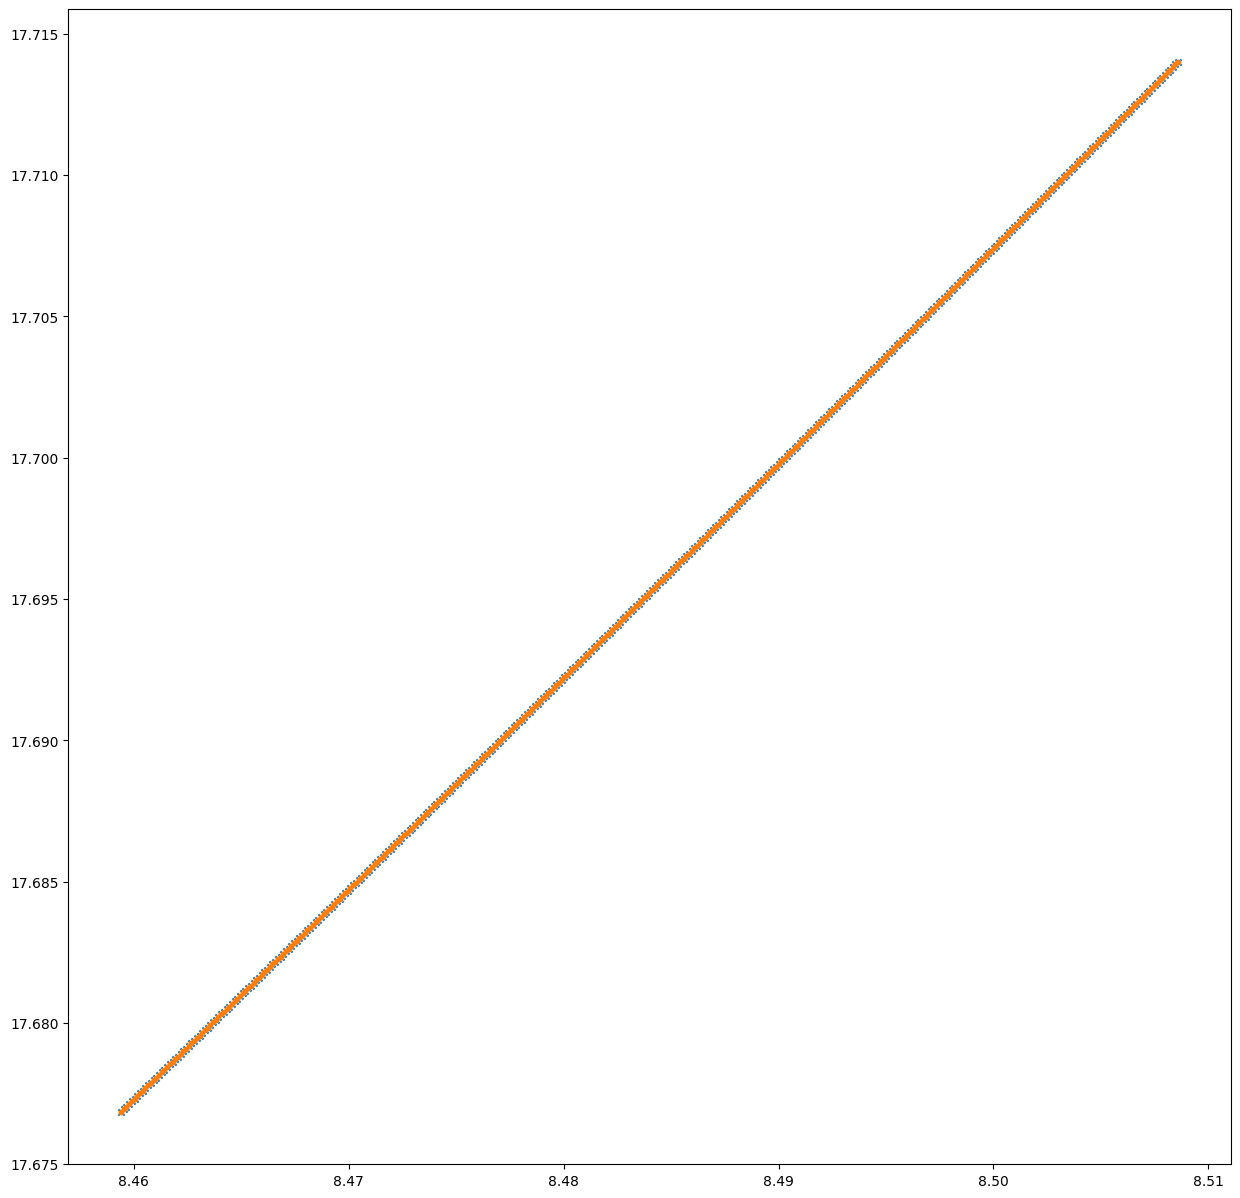

indices =  400 800 163635
outdices =  400 800
163635
400 400


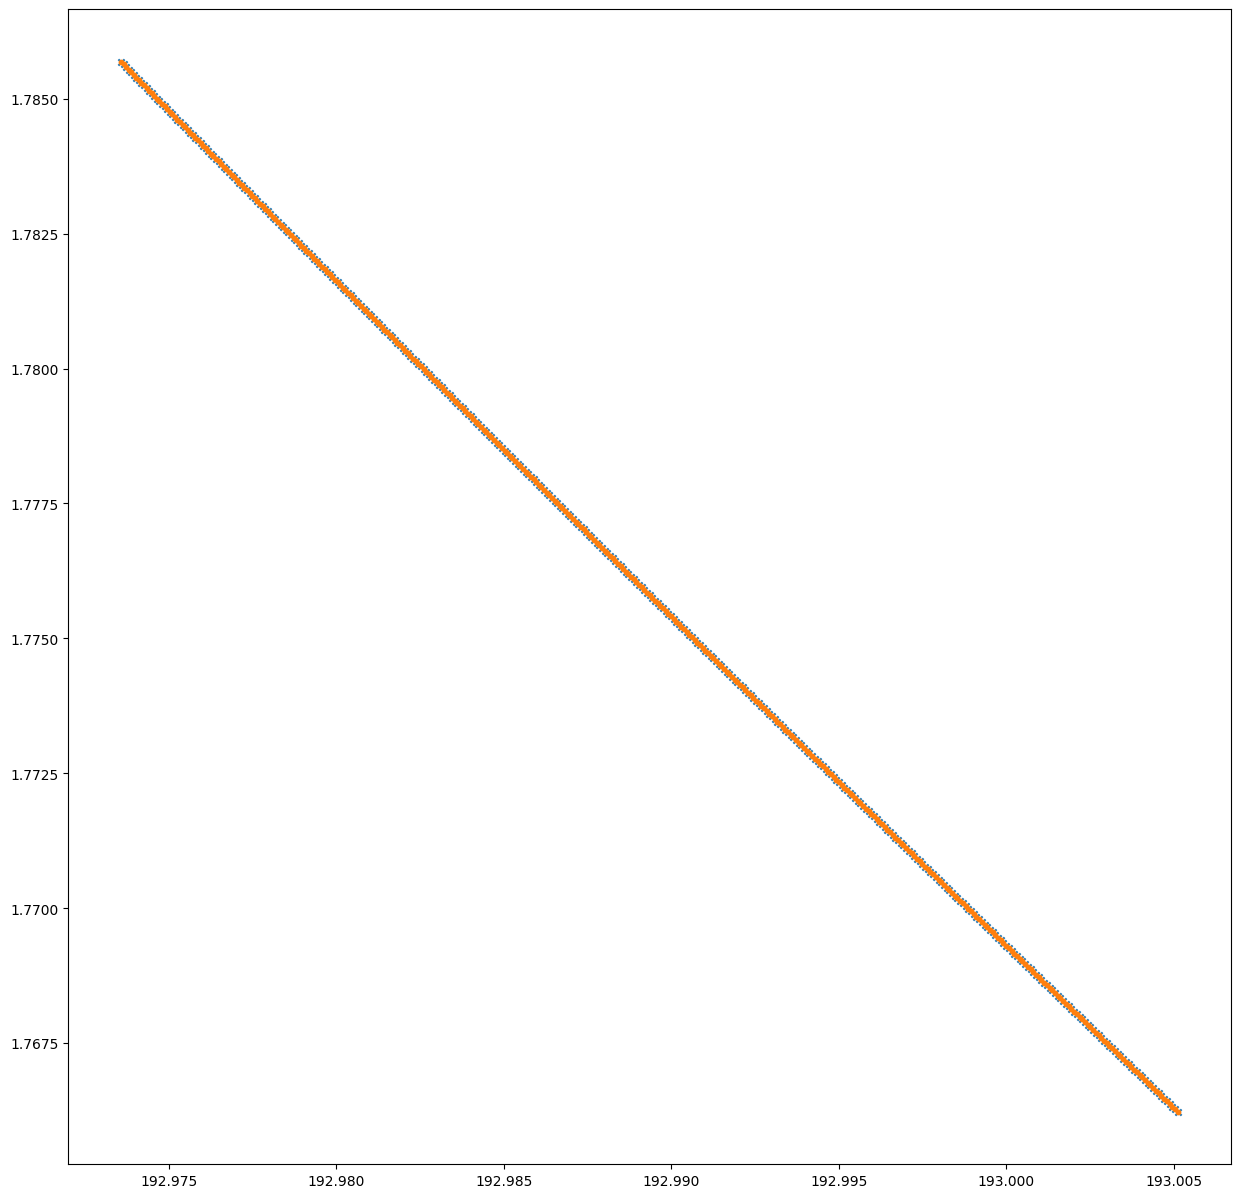

indices =  800 1200 2014 NL92
outdices =  800 1200
2014 NL92
400 400


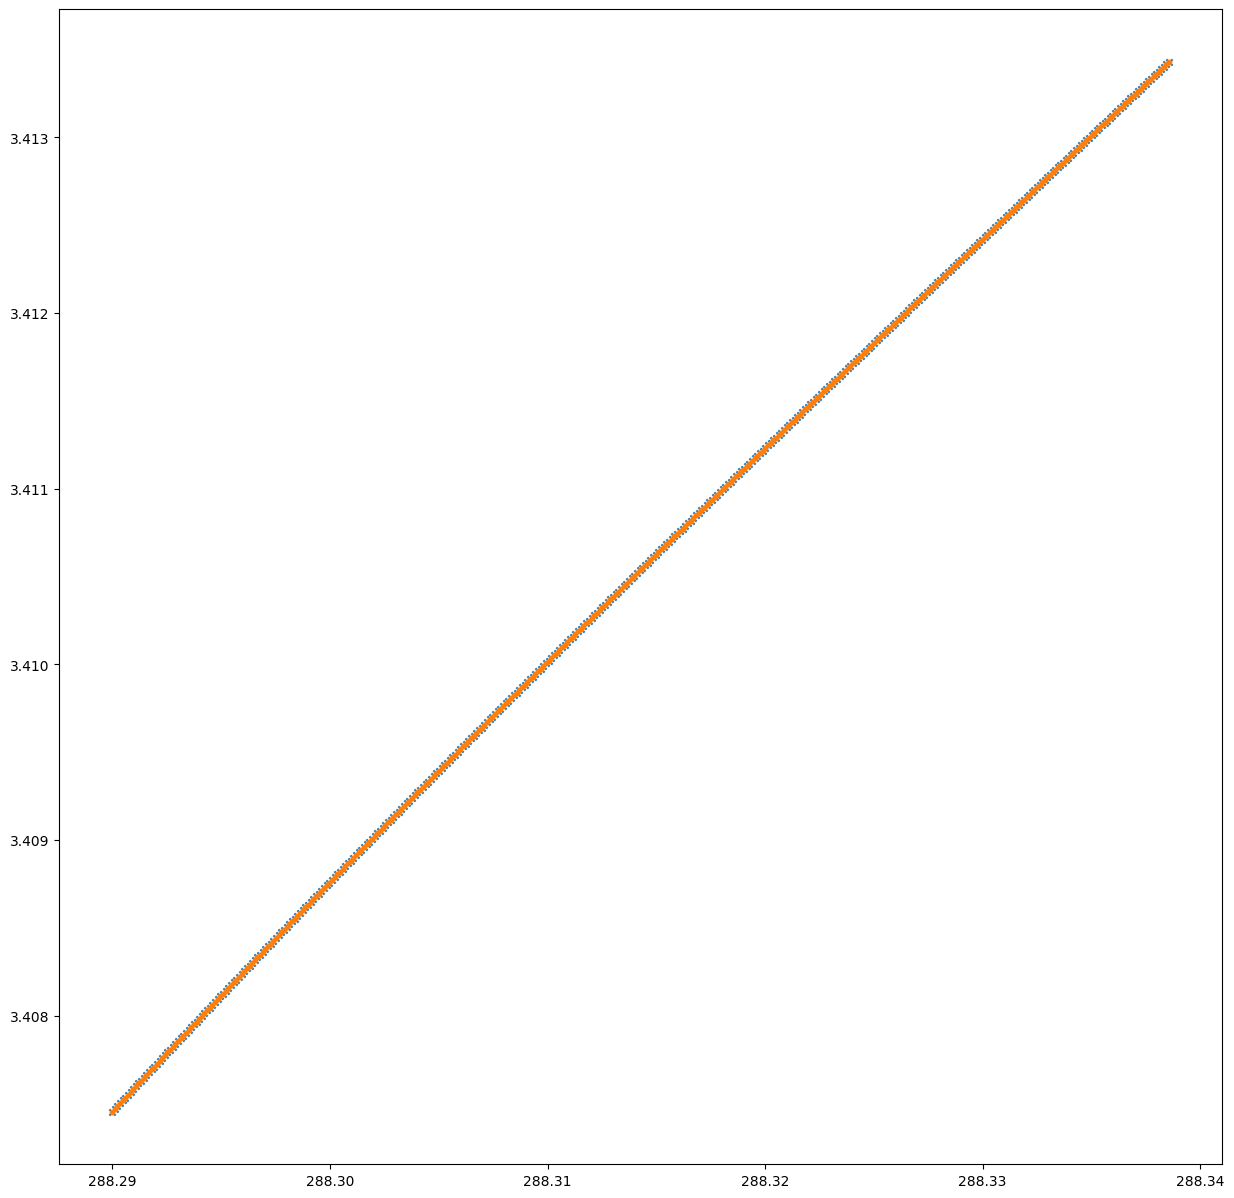

indices =  1200 1600 2022 QG28
outdices =  1200 1600
2022 QG28
400 400


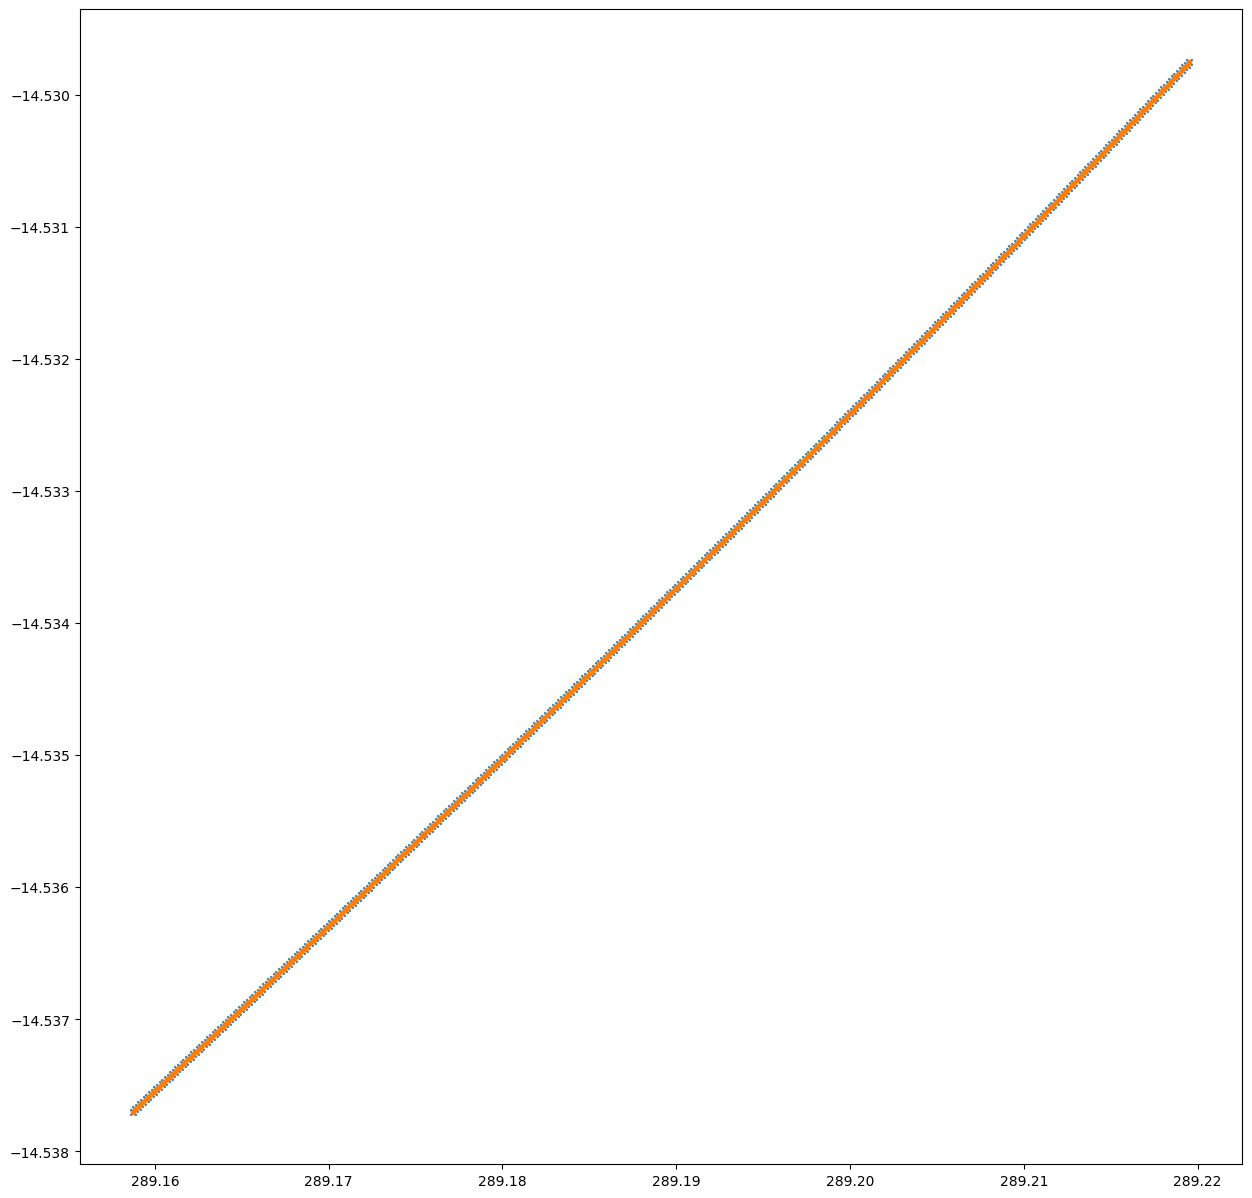

indices =  1600 2000 279999
outdices =  1600 2000
279999
400 400


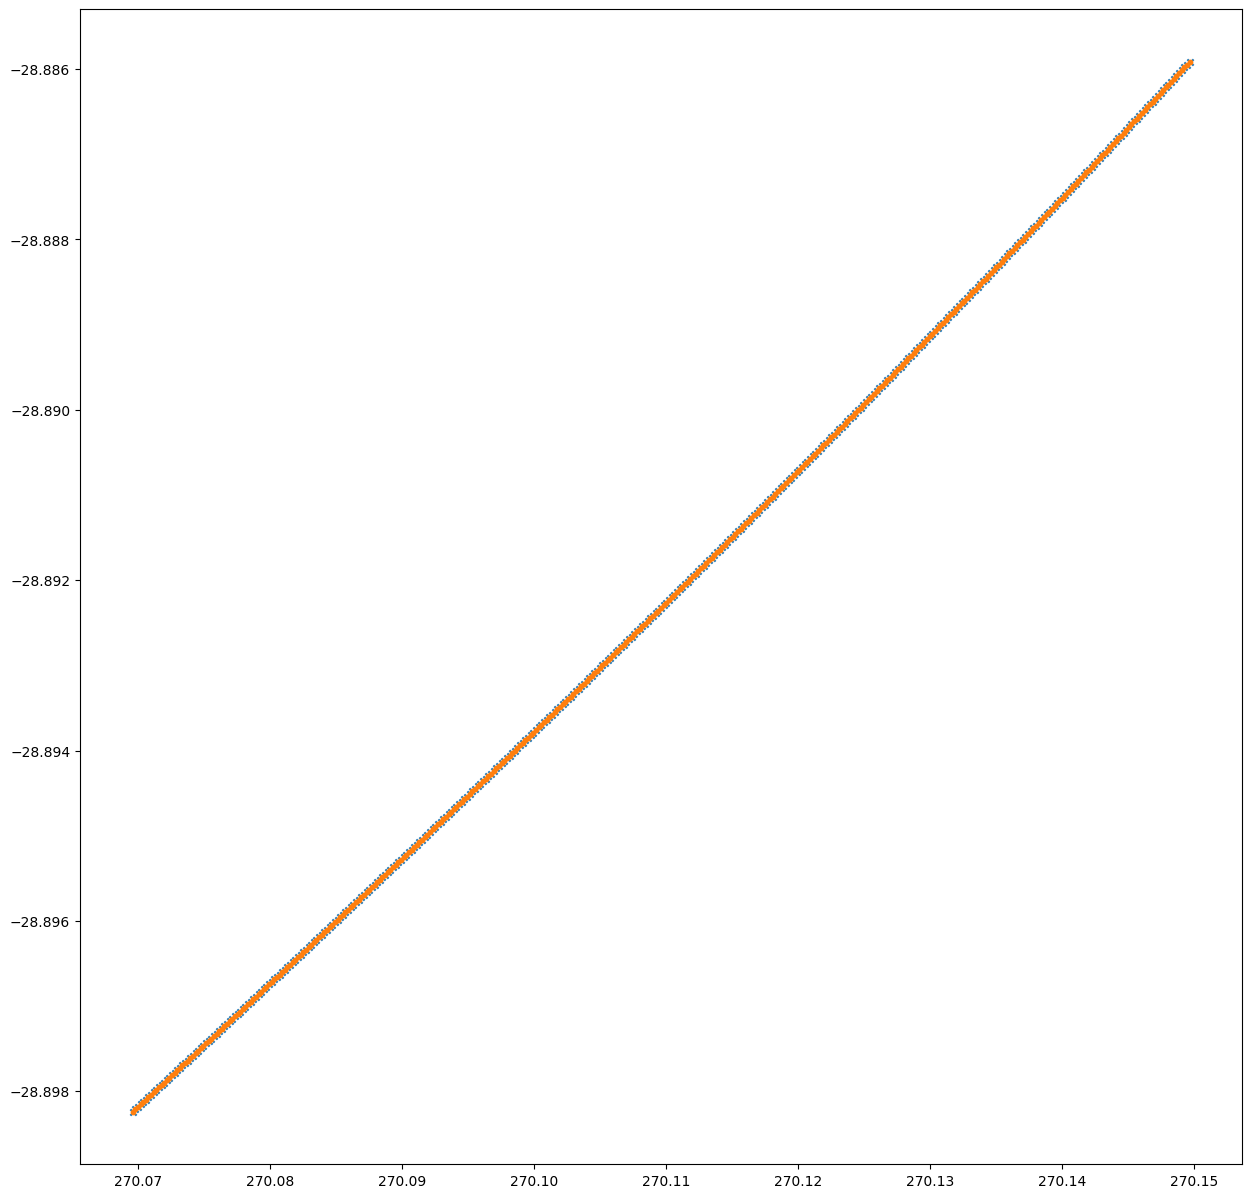

indices =  2000 2400 350412
outdices =  2000 2400
350412
400 400


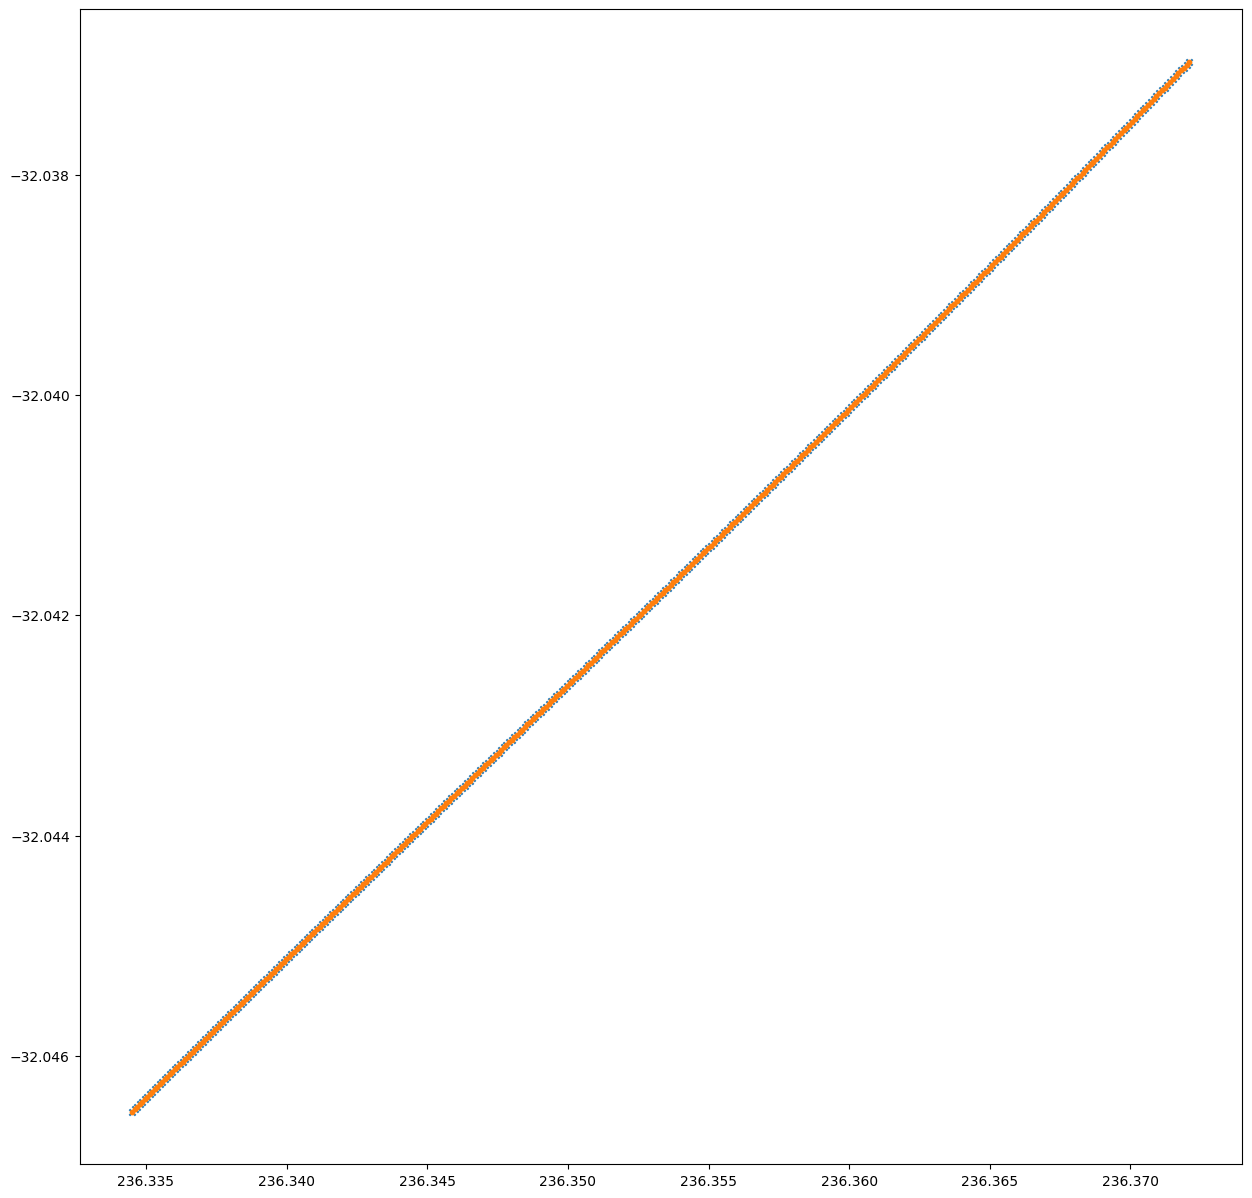

indices =  2400 2800 54533
outdices =  2400 2800
54533
400 400


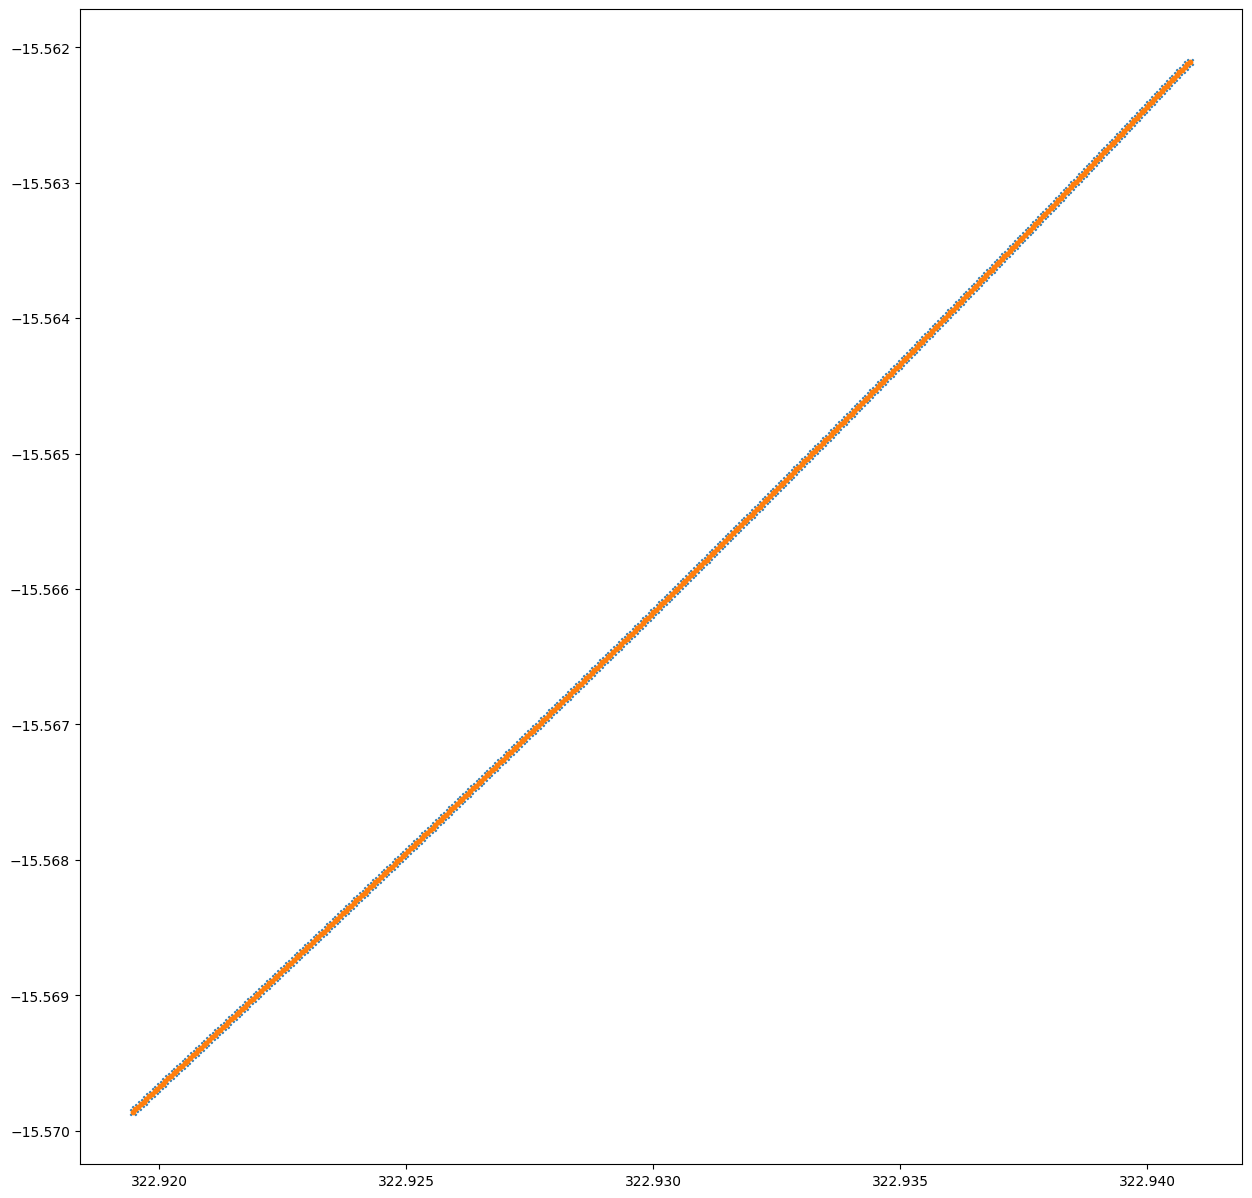

indices =  2800 3200 80464
outdices =  2800 3200
80464
400 400


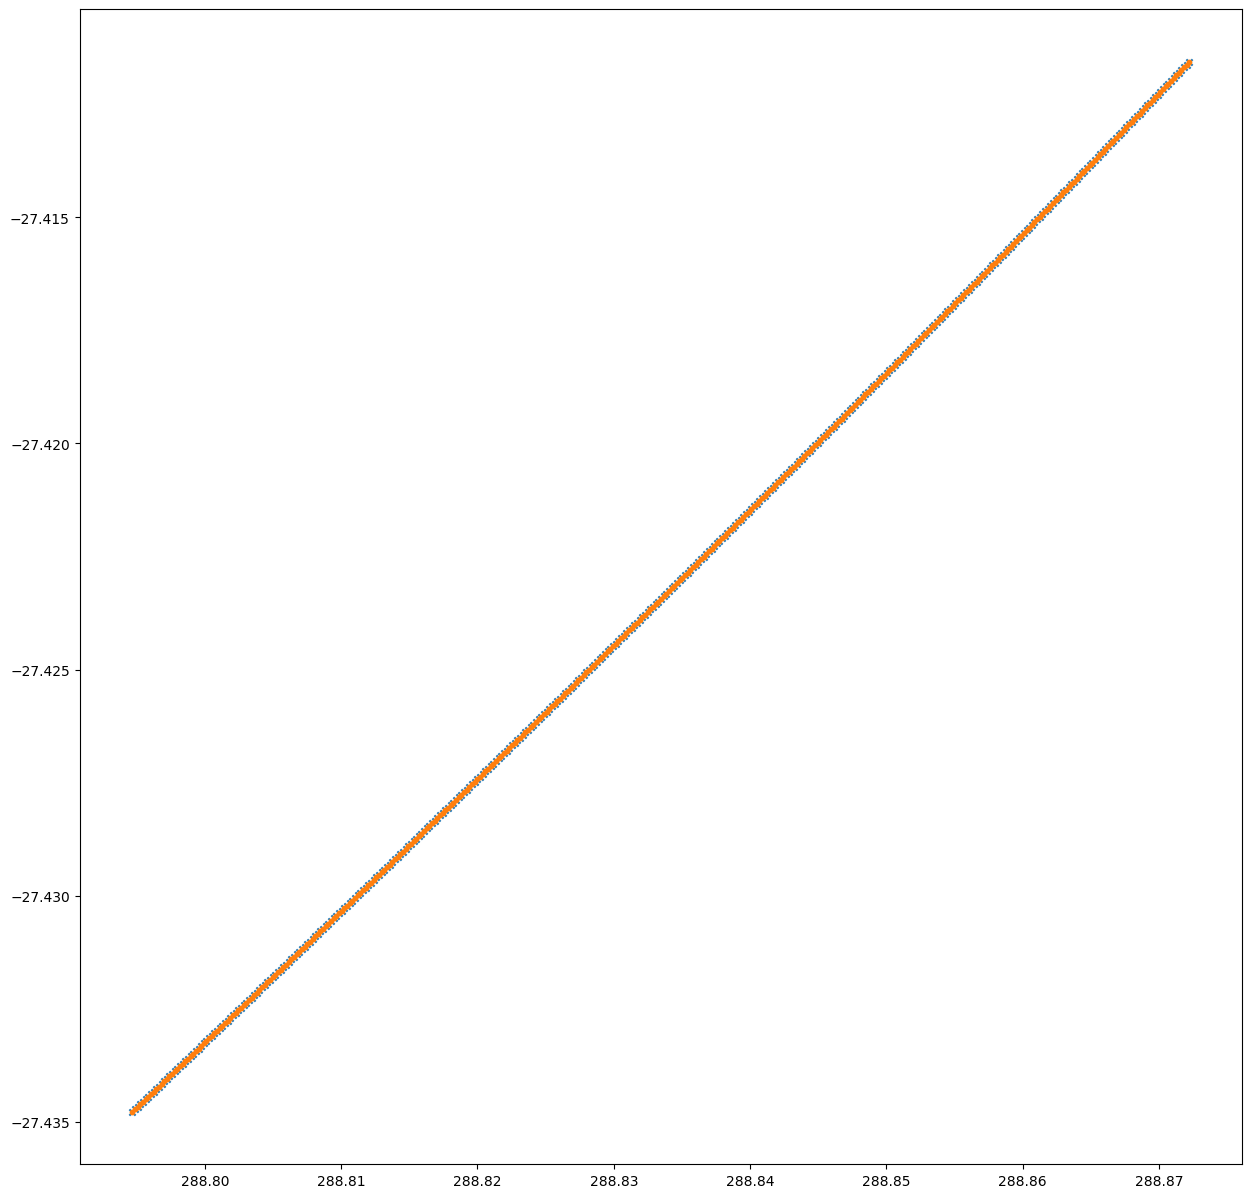

indices =  3200 3600 87884
outdices =  3200 3600
87884
400 400


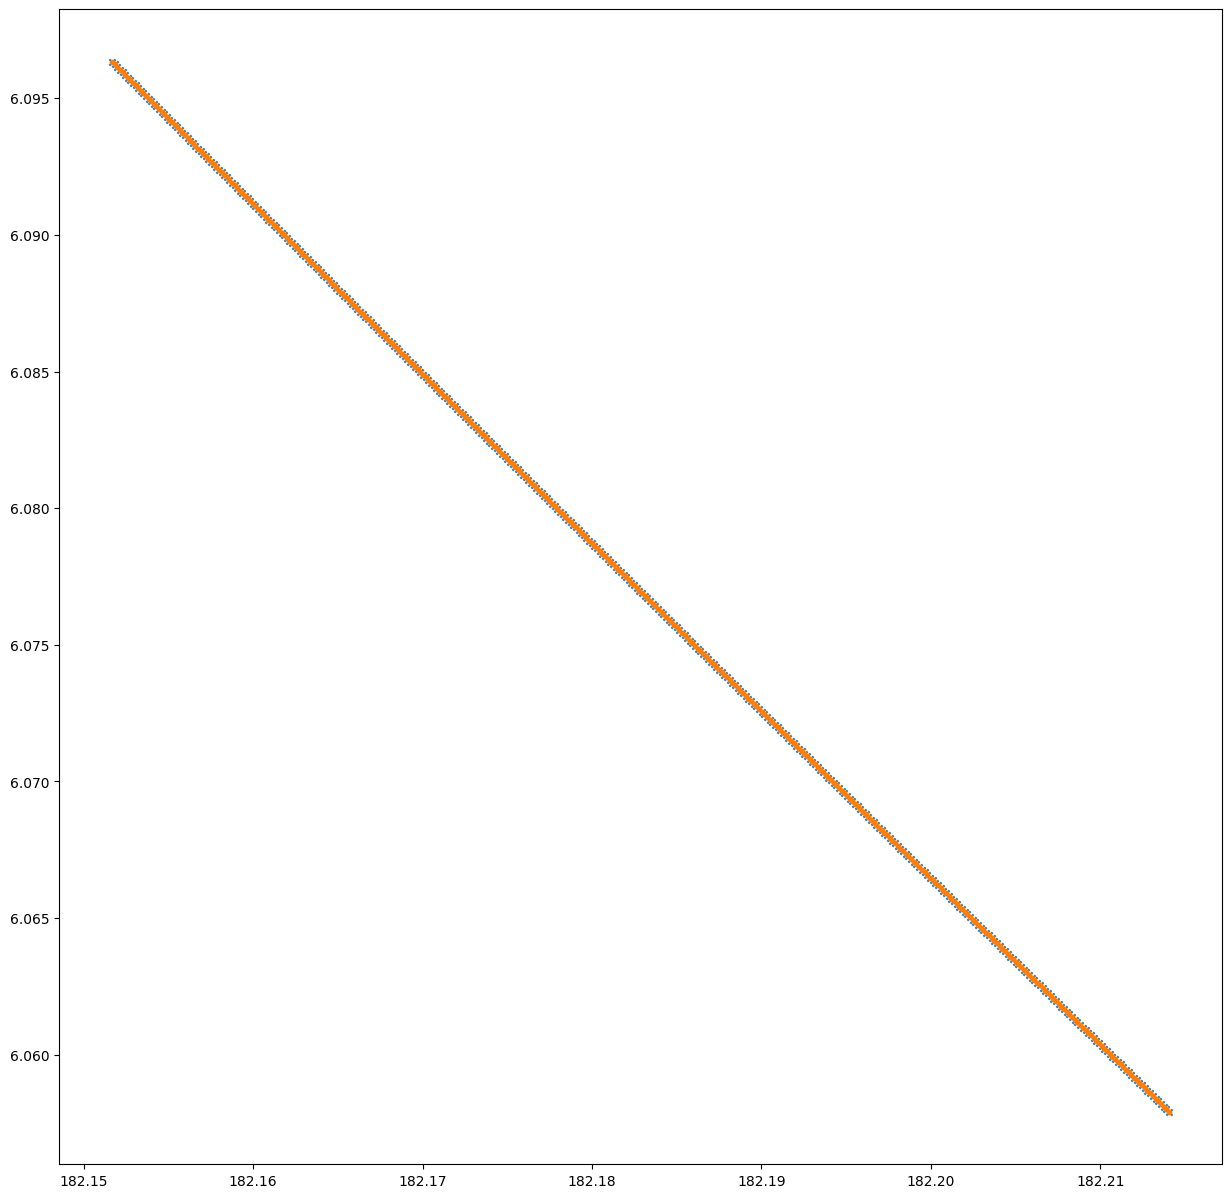

indices =  3600 4399 97214
outdices =  3600 4000
97214
799 799


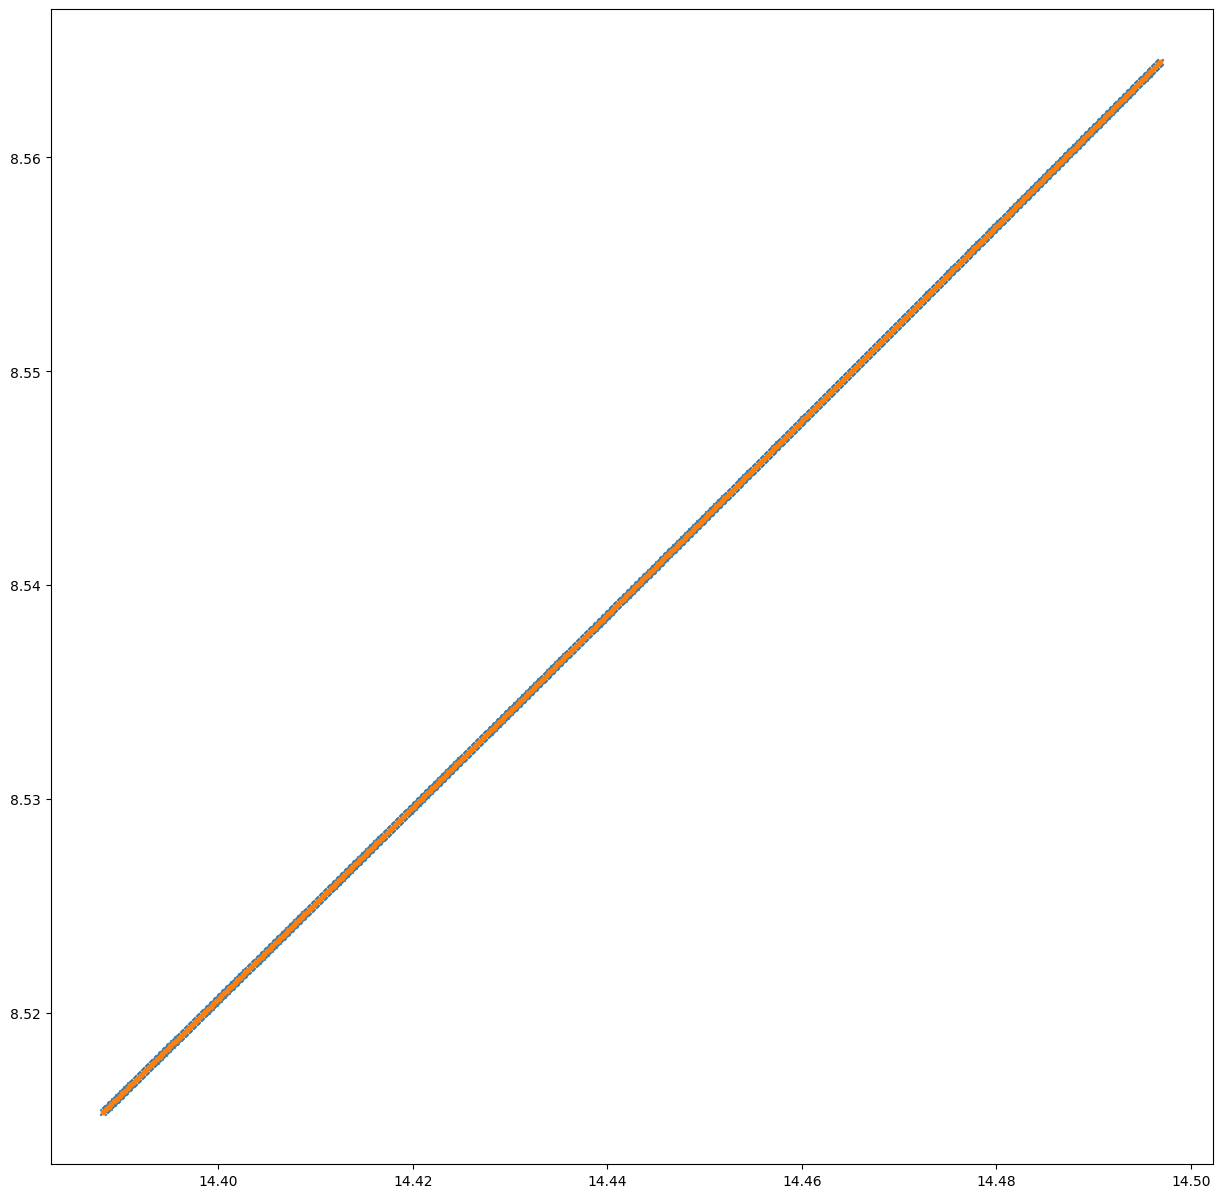

In [ ]:
# Visually confirm that the interpolation has worked as expected, interpolated ephems are still overlapping correctly with the sampled ephems

for obj in range(n_objects):

    ind_start,ind_end = offsets[obj],offsets[obj+1]
    out_ind_start,out_ind_end = obj*n_epochs,(obj+1)*n_epochs
    print("indices = ",ind_start,ind_end,unique_desigs[obj])
    print("outdices = ",out_ind_start,out_ind_end)
    print(night_ephems_keep.column("designation").to_numpy()[ind_start:ind_end][0])

    obj_test = night_ephems_keep.filter(pc.field("designation") == unique_desigs[obj])
    print(ind_end-ind_start,len(obj_test))

    plt.figure(figsize=(15,15))
    plt.gca().get_xaxis().get_major_formatter().set_useOffset(False)
    plt.gca().get_yaxis().get_major_formatter().set_useOffset(False)
    plt.scatter(in_ras[ind_start:ind_end],in_decs[ind_start:ind_end],marker="x",s=20)
    plt.scatter(out_ra[out_ind_start:out_ind_end],out_dec[out_ind_start:out_ind_end],s=10)
    plt.show()

In [ ]:
# Build a table to save with interpolated ephems and the minipix each detection appears in

# get tile & minipix ids
lookup = TanSegmentLookup(
    spacing_deg=(SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC-SegmentationScheme.DEFAULT_OVERLAP_ARCSEC)/3600.0,
    pixel_scale_deg=SegmentationScheme.DEFAULT_PIXEL_SCALE/3600.0,
    dec_min=-90.0,
    ra_min=0.0,
)
tile_ids,minipix_idxs = lookup.query_batch(out_ra,out_dec)
# if you want to combine tile and minipix ids in one string 
#np.array([t.zfill(6)+"_"+m.zfill(4) for t,m in zip(tile_ids.astype(str),minipix_idxs.astype(str))])

# rescale time/coords to same as OG file types
target_epochs_usec = (target_epochs * time_scale).astype(np.int64) # to int64
target_ras_mas = (out_ra * coord_scale).astype(np.int32) # to int32
target_decs_mas = (out_dec * coord_scale).astype(np.int32)

# get columns of designations and target epochs for output table
all_desigs = np.repeat(unique_desigs,n_epochs)
all_epochs = np.tile(target_epochs_usec,n_objects)

# build output table
interpolated_output = pa.table({
    "designation": all_desigs,
    "epoch_tt": all_epochs,
    "ra": target_ras_mas,
    "dec": target_decs_mas,
    "tile_id": tile_ids,
    "minipix_idx": minipix_idxs,
})

In [ ]:
# Save interpolated ephemerides:
pq.write_table(interpolated_output,
                "/net/scratch/kmfas/ephem_samples_3/test.parquet",
                compression="zstd", # need?
                compression_level=3,
                use_dictionary=["designation"],
                column_encoding={
                    "ra": "DELTA_BINARY_PACKED",
                    "dec": "DELTA_BINARY_PACKED",
                    "epoch_tt": "DELTA_BINARY_PACKED",
                    "tile_id": "DELTA_BINARY_PACKED",
                    "minipix_idx": "DELTA_BINARY_PACKED",
                },
                )

## ..Get per-object minipix for interpolated ephems
Determine which minipix an object's detections falls into at argus-like epochs, and associated minipix activation start&duration times

In [29]:
# Get, for each object, then each unique minipix the object appears in, 
# the first and last epoch that the object is in the minipix.  
# This is not a list of completely unique minipix with all 
# start/durations, it's just a per-object unique minipix list
visits = interpolated_output.group_by(['designation','tile_id','minipix_idx']).aggregate([('epoch_tt','min'),('epoch_tt','max')])

# So essentially, each unique minipix may have several activation start & duration periods. 
# We handle this as a separate case.  
# First, (1) we get for each object, for each minipix the object appears in, a start and duration.  

# (1) Get a column of durations for each object's appearance in a minpix, noting:
# "A minipix is considered "active" at time T if T falls within any [start, start + duration) interval"
# ^ https://github.com/argus-hdps/hdps/blob/f264c9c7cba7719846668c95bdab77bcac5c9319/docs/source/technotes/0001-image-format.rst#L381 
# so I add 1 min to each, since the end of the duration is not inclusive
visits = visits.append_column("active_duration",[(visits.column('epoch_tt_max').to_numpy()-visits.column("epoch_tt_min").to_numpy())+(60*1_000_000)])
visits = visits.rename_columns({"epoch_tt_min": "active_start_tt"})
visits = visits.drop("epoch_tt_max")
visits

pyarrow.Table
designation: string
tile_id: int32
minipix_idx: int16
active_start_tt: int64
active_duration: int64
----
designation: [["106532","106532","106532","106532","106532",...,"661766","661766","661766","661766","661766"]]
tile_id: [[284390,284390,284390,284390,284390,...,246925,246925,246925,246925,246925]]
minipix_idx: [[345,409,408,472,471,...,371,307,306,375,305]]
active_start_tt: [[47187660000000,47190240000000,47191620000000,47197020000000,47199180000000,...,47201580000000,47205000000000,47206080000000,47187660000000,47210640000000]]
active_duration: [[2580000000,1380000000,5400000000,2160000000,4680000000,...,3420000000,1080000000,4560000000,900000000,1020000000]]

In [40]:
# save per-object minipix visits: 
pq.write_table(visits.sort_by([("designation","ascending"),("active_start_tt","ascending")]),
                "/net/scratch/kmfas/ephem_samples_3/test_visits.parquet",
                compression="zstd", # need?
                compression_level=3,
                use_dictionary=["designation"],
                column_encoding={
                    "tile_id": "DELTA_BINARY_PACKED",
                    "minipix_idx": "DELTA_BINARY_PACKED",
                    "active_start_tt": "DELTA_BINARY_PACKED",
                    "active_duration": "DELTA_BINARY_PACKED",
                },
                )

In [41]:
pq.read_table("/net/scratch/kmfas/ephem_samples_3/test_visits.parquet")


pyarrow.Table
designation: string
tile_id: int32
minipix_idx: int16
active_start_tt: int64
active_duration: int64
----
designation: [["106532","106532","106532","106532","106532",...,"661766","661766","661766","661766","661766"]]
tile_id: [[284390,284390,284390,284390,284390,...,246925,246925,246925,246925,246925]]
minipix_idx: [[345,409,408,472,471,...,372,371,307,306,305]]
active_start_tt: [[47187660000000,47190240000000,47191620000000,47197020000000,47199180000000,...,47197140000000,47201580000000,47205000000000,47206080000000,47210640000000]]
active_duration: [[2580000000,1380000000,5400000000,2160000000,4680000000,...,4440000000,3420000000,1080000000,4560000000,1020000000]]

In [ ]:
# Second, (2) for each unique minipix that is occupied in this night,
# get all activation start and durations and combine them if durations overlap.
 # this is maybe out of scope.

## ..Checks
I used a python script with the above code to interpolate object ephems for each of the 7 nights of samples Donovan generated.  Here, I make sure those interpolations worked and that the output files look as expected, that any random object I pull from the interp files matches its ephemeris from the OG ephem file.  

In [13]:
# Select a night to check and load (a) the interpolated ephems, (b) the minipix visits 

# night
night = "20260701" # string YYYYMMDD

# interpolated ephems
interped_ephems = pq.read_table("/net/scratch/kmfas/ephem_samples_3/"+night+"_sso_detections.parquet")

# minipix of interpolated ephems
interped_ephem_minipix = pq.read_table("/net/scratch/kmfas/ephem_samples_3/"+night+"_sso_minipix_visits.parquet")


In [ ]:
interped_ephem_desigs = pc.cast(interped_ephems.column('designation'), pa.string())
interped_ephem_mask = pc.is_in(interped_ephem_desigs,value_set=keep_desigs)
interped_ephems_keep = interped_ephems.filter(interped_ephem_mask)
len(interped_ephems_keep)

20736000

In [9]:
print(f"{len(interped_ephems)} detections of {len(pc.unique(interped_ephems["designation"]))} objects in night {night}")


77507200 detections of 193768 objects in night 20260701


In [16]:
interped_ephem_minipix_desigs = pc.cast(interped_ephem_minipix.column('designation'), pa.string())
interped_ephem_minipix_mask = pc.is_in(interped_ephem_minipix_desigs,value_set=keep_desigs)
interped_ephems_minipix_keep = interped_ephem_minipix.filter(interped_ephem_minipix_mask)
len(interped_ephems_minipix_keep)

501007

In [ ]:
len(interped_ephem_minipix)

1850110

In [32]:
# Check an object to make sure the interpolated ephem matches the og ephem 

# select an object by defining designation, or choosing a random one
test_desig = '674535'
#unique_desigs = np.unique(interped_ephems.column("designation").to_numpy())
#rand_desig_index = random.randint(0,len(unique_desigs))
#test_desig = unique_desigs[rand_desig_index]

# get ephem from the interpolated file 
# test of random sample of objects done in this notebook 
#interp_test = pq.read_table("/net/scratch/kmfas/ephem_samples_3/test.parquet")
# or a full night of interpolation done by py script
test_obj_interp = interped_ephems.filter(pc.field("designation")==test_desig)

# get ephem from the og ephems file
ephem_diro = "/net/scratch/dschlekat/ephemeris_samples3/"+night[:4]+"-"+night[4:6]+"-"+night[6:]
ephems = pq.read_table(ephem_diro+"/ephemerides.parquet") 
test_obj_ephem = ephems.filter(pc.field("designation")==test_desig)

plt.scatter(test_obj_ephem.column("ra").to_numpy().astype(np.float64)/coord_scale,test_obj_ephem.column("dec").to_numpy().astype(np.float64)/coord_scale,marker="x")
plt.scatter(test_obj_interp.column("ra").to_numpy().astype(np.float64)/coord_scale,test_obj_interp.column("dec").to_numpy().astype(np.float64)/coord_scale,marker=".")


plt.gca().get_xaxis().get_major_formatter().set_useOffset(False)
plt.gca().get_yaxis().get_major_formatter().set_useOffset(False)
plt.show()

NameError: name 'coord_scale' is not defined

# Graveyard of ideas
Approach options:

1.  use sample and linearly interpolate between sample epochs to some common image epochs
    a.  come up with some fake image epochs (1 minute apart for span of dark window of each night)
    b.  lim mag cut in V 
    c.  interpolate each surviving object to the fake image epochs 
2.  use the hdps.catalogs.movers.finder module to find movers in a bunch of fake images 
    a.  create some fake images with fake wcs objects (make hdps.core.FullFrameImage instances for each fake image epoch, create that list of 1-minute-spaced epochs for entire dark window for each night) and fake fovs 
    b.  use finder.MoverFinder.find_movers_batch() to 
3.  
